In [2]:
## UAS-guided airborne MSI analysis for LAI modeling in Fynbos shrublands
## Author: Ramesh Bhatta, RIT
## Contact: rb1005@rit.edu

"""

This notebook contains the airborne MSI-equivalent analysis used in the paper.
AVIRIS-NG is convolved with the measured Mavic 3M spectral response functions, matched to UAS
observations at native AVIRIS-NG support, and evaluated using spatially separated harmonization.

"""

'\n\nThis notebook contains the airborne MSI-equivalent analysis used in the paper.\nAVIRIS-NG is convolved with the measured Mavic 3M spectral response functions, matched to UAS\nobservations at native AVIRIS-NG support, and evaluated using spatially separated harmonization.\n\n'

In [3]:
## Necessary imports and global variables

from pathlib import Path
from itertools import product
import os

import numpy as np
import pandas as pd
import geopandas as gpd

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

import rasterio
from rasterio.windows import Window
from rasterio.mask import mask as raster_mask
from rasterio.features import geometry_mask, geometry_window
from rasterio.errors import WindowError

from netCDF4 import Dataset

from shapely.geometry import Polygon, box, mapping
from shapely.ops import transform as shapely_transform
from shapely.affinity import translate as shapely_translate

from pyproj import Transformer

from scipy.spatial import cKDTree
from scipy.stats import pearsonr

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from IPython.display import display

pd.set_option("display.max_columns", 100); pd.set_option("display.width", 200)

# Input data used by the final revision analysis
UAS_FILES = {
    "BY_2006": "../Drone_msi_data/burn2006_lr_band_stack.tif", "BY_2016": "../Drone_msi_data/burn2016_lr_band_stack.tif",
    "BY_2019": "../Drone_msi_data/burn2019_lr_band_stack.tif", "BY_2020": "../Drone_msi_data/burn2020_lr_band_stack.tif",
    "BY_2017_16": "../Drone_msi_data/burn2017_2016_lr_band_stack.tif",
}

AVIRIS_L2B = {
    "ang20231031t092656_002": Path("../../AVIRIS_NG_data/ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc"),
    "ang20231109t062226_001": Path("../../AVIRIS_NG_data/ang20231109t062226_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc"),
    "ang20231109t062226_002": Path("../../AVIRIS_NG_data/ang20231109t062226_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc"),
    "ang20231117t123306_001": Path("../../AVIRIS_NG_data/ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc"),
}

SRF_FILES = {
    "Green": Path("../Mavic3m_srf/Mavic3-MS_G_filter.csv"), "Red": Path("../Mavic3m_srf/Mavic3-MS_R_filter.csv"),
    "RedEdge": Path("../Mavic3m_srf/Mavic3-MS_RE_filter.csv"), "NIR": Path("../Mavic3m_srf/Mavic3-MS_IR_filter.csv"),
}

LAI_SHAPEFILE = Path("./ground_LAI_data_processed/5mx5m_LAI_plots.shp")

ANCHOR_BANDS = ["Green", "Red", "RedEdge", "NIR"]
ANCHOR_WAVELENGTHS = None
EPS, VALID_TOL = 1e-6, 1e-12
STRICT_INTERIOR_VALID_FRACTION = 1.0
N_SPATIAL_FOLDS, PRIMARY_BUFFER_PIXELS = 5, 1
EXPECTED_LAI_N, EXPECTED_COMMON_UAS_N = 20, 11
EXPECTED_STRICT_INTERIOR_N, EXPECTED_DEPLOY_N = 2147, 2006

ANCHOR_RF_KWARGS = {
    "n_estimators": 300, "min_samples_leaf": 10, "max_features": 4,
    "max_depth": 6, "random_state": 42, "n_jobs": -1,
}

BAND_COLORS = {"Green": "#2ca02c", "Red": "#d62728", "RedEdge": "#9467bd", "NIR": "#1f77b4"}
RECOVERY_COLORS = {"Mature": "#1f77b4", "Mid-recovery": "#2ca02c", "Young": "#ff7f0e"}


# Final revision settings used by the cells below
FIXED_UAS_TRANSFER_INDEX, FIXED_UAS_TRANSFER_FORM = "GDVI", "Quadratic"
RUN_SCALE_SITE_DIAGNOSTICS = True
RUN_L2A_SENSITIVITY = True
RUN_COREGISTRATION_SENSITIVITY = True
HSI_INDEX_NAMES = [
    "NDVI", "SR", "GNDVI", "GRVI", "GDVI", "SAVI", "GSAVI", "OSAVI", "MSAVI2",
    "NDRE", "SR_RE", "CI_RE", "MTCI", "MSR", "EVI2", "NDWI", "CAI", "NDLI",
    "Custom_SWIR_Primary", "Custom_NIR_Plateau", "Custom_VIS_Green", "Custom_SWIR1_Bridge",
    "NIRv", "SATVI", "NDTI", "SINDRI", "LCA", "MTVI2",
]

TARGET_MAP = {"Green":"UAS_Green", "Red":"UAS_Red", "RedEdge":"UAS_RedEdge", "NIR":"UAS_NIR"}
RAW_TARGET_MAP = {
    "Green": ("UAS_Green", "Raw_Green"), "Red": ("UAS_Red", "Raw_Red"),
    "RedEdge": ("UAS_RedEdge", "Raw_RedEdge"), "NIR": ("UAS_NIR", "Raw_NIR"),
}


In [ ]:
## A1. Load AVIRIS-NG wavelengths, measured Mavic 3M SRFs, and shared helpers

def read_wavelengths(nc_path):
    with Dataset(nc_path, mode='r') as ds:
        return np.asarray(ds.groups['reflectance'].variables['wavelength'][:], dtype=float)

def load_srf_curve(csv_path):
    df = pd.read_csv(csv_path)
    if df.shape[1] < 2:
        raise ValueError(f'{csv_path} must contain wavelength and response columns.')
    wl = df.iloc[:, 0].to_numpy(dtype=float)
    response = df.iloc[:, 1].to_numpy(dtype=float)
    valid = np.isfinite(wl) & np.isfinite(response)
    wl = wl[valid]
    response = response[valid]
    if np.nanmedian(wl) < 10:
        wl = wl * 1000.0
    order = np.argsort(wl)
    return (wl[order], response[order])

scene_wavelengths = {scene: read_wavelengths(path) for scene, path in AVIRIS_L2B.items()}
reference_scene = next(iter(scene_wavelengths))
wavelengths = scene_wavelengths[reference_scene].copy()

for scene, wl in scene_wavelengths.items():
    if len(wl) != len(wavelengths) or not np.allclose(wl, wavelengths, atol=1e-06, rtol=0):
        raise RuntimeError(f'{scene} does not share the common AVIRIS wavelength grid.')
native_srf = {band: load_srf_curve(path) for band, path in SRF_FILES.items()}
srf_effective_wavelengths = {}

for band in ANCHOR_BANDS:
    srf_wl, srf_response = native_srf[band]
    response = np.clip(np.asarray(srf_response, dtype=float), 0, None)
    if response.sum() <= 0:
        raise RuntimeError(f'{band}: invalid measured SRF.')
    srf_effective_wavelengths[band] = float(np.sum(np.asarray(srf_wl, dtype=float) * response) / np.sum(response))
ANCHOR_WAVELENGTHS = np.array([srf_effective_wavelengths[band] for band in ANCHOR_BANDS], dtype=float)

if not np.all(np.diff(ANCHOR_WAVELENGTHS) > 0):
    raise RuntimeError('Measured SRF effective wavelengths are not strictly increasing.')
srf_weights = {}

for band in ANCHOR_BANDS:
    srf_wl, srf_response = native_srf[band]
    response = np.interp(wavelengths, srf_wl, srf_response, left=0.0, right=0.0)
    response = np.clip(response, 0, None)
    if response.sum() <= 0:
        raise RuntimeError(f'No AVIRIS overlap with the {band} Mavic SRF.')
    full_weights = response / response.sum()
    idx = np.where(full_weights > 0)[0]
    srf_weights[band] = {'indices': idx, 'weights': full_weights[idx], 'full_weights': full_weights}

def synthesize_srf_anchors(spectrum):
    """
    Integrate one AVIRIS spectrum through the measured Mavic SRFs.
    """
    spectrum = np.asarray(spectrum, dtype=float)
    out = {}
    for band in ANCHOR_BANDS:
        info = srf_weights[band]
        vals = spectrum[info['indices']]
        if not np.isfinite(vals).all():
            out[band] = np.nan
        else:
            out[band] = float(np.sum(vals * info['weights']))
    return out

def synthesize_srf_anchor_matrix(spectra):
    """
    Vectorized Mavic-SRF integration for an n × wavelength matrix.
    """
    spectra = np.asarray(spectra, dtype=float)
    if spectra.ndim != 2:
        raise ValueError('spectra must be a 2-D [sample, wavelength] array.')
    out = {}
    for band in ANCHOR_BANDS:
        info = srf_weights[band]
        vals = spectra[:, info['indices']]
        out[band] = np.sum(vals * info['weights'][None, :], axis=1)
    return out

gain_basis_columns = []
for j in range(len(ANCHOR_BANDS)):
    knot_values = np.zeros(len(ANCHOR_BANDS), dtype=float)
    knot_values[j] = 1.0
    basis_j = np.interp(wavelengths, ANCHOR_WAVELENGTHS, knot_values, left=knot_values[0], right=knot_values[-1])
    gain_basis_columns.append(basis_j)
GAIN_BASIS = np.column_stack(gain_basis_columns)

if not np.allclose(GAIN_BASIS.sum(axis=1), 1.0, atol=1e-12):
    raise RuntimeError('Piecewise-linear gain basis does not form a partition of unity.')

def solve_srf_constrained_gain(spectrum, target_anchors):
    """
    Solve the four gain-knot coefficients so that the SRF-integrated
    harmonized spectrum reproduces the four RF-predicted UAS bands.

    The harmonized spectrum is:

        Rh(λ) = Rraw(λ) * Σ_j c_j B_j(λ)

    and the four coefficients c_j are obtained from a 4 × 4 linear
    system formed by integrating Rraw(λ) B_j(λ) through each Mavic SRF.
    """

    spectrum = np.asarray(spectrum, dtype=float)
    target = np.asarray([target_anchors[band] for band in ANCHOR_BANDS], dtype=float)

    if not np.isfinite(target).all():
        raise ValueError('Non-finite target anchors.')
    M = np.zeros((len(ANCHOR_BANDS), len(ANCHOR_BANDS)), dtype=float)
    for i, band in enumerate(ANCHOR_BANDS):
        info = srf_weights[band]
        idx = info['indices']
        w = info['weights']
        raw_vals = spectrum[idx]
        if not np.isfinite(raw_vals).all():
            raise ValueError(f'Non-finite spectrum within {band} SRF.')
        for j in range(len(ANCHOR_BANDS)):
            M[i, j] = np.sum(raw_vals * GAIN_BASIS[idx, j] * w)
    condition_number = float(np.linalg.cond(M))
    try:
        knot_gains = np.linalg.solve(M, target)
        solver = 'solve'
    except np.linalg.LinAlgError:
        knot_gains = np.linalg.lstsq(M, target, rcond=None)[0]
        solver = 'lstsq'

    gain_curve = GAIN_BASIS @ knot_gains
    harmonized_spectrum = spectrum * gain_curve
    reconstructed = synthesize_srf_anchors(harmonized_spectrum)
    reconstructed_vector = np.asarray([reconstructed[band] for band in ANCHOR_BANDS], dtype=float)
    residual = reconstructed_vector - target
    return {'harmonized_spectrum': harmonized_spectrum, 'gain_curve': gain_curve, 'knot_gains': knot_gains, 'condition_number': condition_number, 'solver': solver, 'reconstructed_anchors': reconstructed, 'anchor_residuals': residual, 'max_abs_anchor_residual': float(np.max(np.abs(residual)))}

print(f'Verified common AVIRIS wavelength grid: {len(wavelengths)} bands.')
print('\nMeasured Mavic SRF effective wavelengths:')
display(pd.DataFrame({'Band': ANCHOR_BANDS, 'Effective_wavelength_nm': ANCHOR_WAVELENGTHS}).round(3))

def prediction_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[valid]
    y_pred = y_pred[valid]
    if len(y_true) < 2:
        return {'n': len(y_true), 'R2': np.nan, 'RMSE': np.nan, 'MAE': np.nan, 'Bias': np.nan, 'r': np.nan}
    return {'n': len(y_true), 'R2': r2_score(y_true, y_pred), 'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)), 'MAE': mean_absolute_error(y_true, y_pred), 'Bias': float(np.mean(y_pred - y_true)), 'r': float(np.corrcoef(y_true, y_pred)[0, 1])}

def centered_r(y_true, y_pred, groups):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    groups = np.asarray(groups)
    valid = np.isfinite(y_true) & np.isfinite(y_pred) & pd.notna(groups)
    y_true = y_true[valid]
    y_pred = y_pred[valid]
    groups = groups[valid]
    yc = np.full(len(y_true), np.nan)
    pc = np.full(len(y_pred), np.nan)
    for g in np.unique(groups):
        m = groups == g
        yc[m] = y_true[m] - np.mean(y_true[m])
        pc[m] = y_pred[m] - np.mean(y_pred[m])
    if np.std(yc) <= 0 or np.std(pc) <= 0:
        return np.nan
    return float(np.corrcoef(yc, pc)[0, 1])

def fit_predict_form(x_train, y_train, x_test, form):
    degree = 1 if form == 'Linear' else 2
    coef = np.polyfit(np.asarray(x_train, dtype=float), np.asarray(y_train, dtype=float), degree)
    return np.polyval(coef, np.asarray(x_test, dtype=float))

def evaluate_single_index(x, y, form):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]
    degree = 1 if form == 'Linear' else 2
    coef = np.polyfit(x, y, degree)
    fitted = np.polyval(coef, x)
    loo = LeaveOneOut()
    cv_pred = np.full(len(y), np.nan, dtype=float)
    for tr, te in loo.split(x):
        cv_pred[te] = fit_predict_form(x[tr], y[tr], x[te], form)
    return {'n': len(y), 'Full_R2': r2_score(y, fitted), 'Full_RMSE': np.sqrt(mean_squared_error(y, fitted)), 'LOOCV_R2': r2_score(y, cv_pred), 'LOOCV_RMSE': np.sqrt(mean_squared_error(y, cv_pred)), 'LOOCV_MAE': mean_absolute_error(y, cv_pred), 'LOOCV_pred': cv_pred}

def calculate_hsi_indices(X_mat, wave_arr):
    X_mat = np.asarray(X_mat, dtype=float)
    wave_arr = np.asarray(wave_arr, dtype=float)
    targets = [480, 527.4, 531, 547.4, 550, 570, 670, 681, 709, 720, 754, 800, 850, 860, 1240, 1243.6, 1288.7, 1650, 1680, 1729.5, 1749.5, 1750, 2005, 2100, 2210, 2260, 2320.5, 2330]
    b = {w: X_mat[:, np.argmin(np.abs(wave_arr - w))] for w in targets}
    ndvi = (b[850] - b[670]) / (b[850] + b[670] + EPS)
    return {'NDVI': ndvi, 'SR': b[850] / (b[670] + EPS), 'GNDVI': (b[850] - b[550]) / (b[850] + b[550] + EPS), 'GRVI': (b[550] - b[670]) / (b[550] + b[670] + EPS), 'GDVI': b[850] - b[550], 'SAVI': 1.5 * (b[850] - b[670]) / (b[850] + b[670] + 0.5 + EPS), 'GSAVI': 1.5 * (b[850] - b[550]) / (b[850] + b[550] + 0.5 + EPS), 'OSAVI': 1.16 * (b[850] - b[670]) / (b[850] + b[670] + 0.16 + EPS), 'MSAVI2': 0.5 * (2 * b[850] + 1 - np.sqrt(np.maximum((2 * b[850] + 1) ** 2 - 8 * (b[850] - b[670]), 0))), 'NDRE': (b[850] - b[720]) / (b[850] + b[720] + EPS), 'SR_RE': b[850] / (b[720] + EPS), 'CI_RE': b[850] / (b[720] + EPS) - 1, 'MTCI': (b[754] - b[709]) / (b[709] - b[681] + EPS), 'MSR': (b[850] / (b[670] + EPS) - 1) / (np.sqrt(np.maximum(b[850] / (b[670] + EPS), 0)) + 1), 'EVI2': 2.5 * (b[850] - b[670]) / (b[850] + 2.4 * b[670] + 1 + EPS), 'NDWI': (b[860] - b[1240]) / (b[860] + b[1240] + EPS), 'CAI': 0.5 * (b[2005] + b[2210]) - b[2100], 'NDLI': (np.log(1 / (b[1750] + EPS)) - np.log(1 / (b[1680] + EPS))) / (np.log(1 / (b[1750] + EPS)) + np.log(1 / (b[1680] + EPS)) + EPS), 'Custom_SWIR_Primary': (b[2320.5] - b[2005]) / (b[2320.5] + b[2005] + EPS), 'Custom_NIR_Plateau': (b[1288.7] - b[1243.6]) / (b[1288.7] + b[1243.6] + EPS), 'Custom_VIS_Green': (b[547.4] - b[527.4]) / (b[547.4] + b[527.4] + EPS), 'Custom_SWIR1_Bridge': (b[1749.5] - b[1729.5]) / (b[1749.5] + b[1729.5] + EPS), 'NIRv': ndvi * b[850], 'SATVI': 1.5 * (b[1650] - b[670]) / (b[1650] + b[670] + 0.5 + EPS) - b[2210] / 2.0, 'NDTI': (b[1650] - b[2210]) / (b[1650] + b[2210] + EPS), 'SINDRI': (b[2210] - b[2260]) / (b[2210] + b[2260] + EPS), 'LCA': 100 * (2.0 * b[2210] - (b[2100] + b[2330])), 'MTVI2': 1.5 * (1.2 * (b[800] - b[550]) - 2.5 * (b[670] - b[550])) / np.sqrt(np.maximum((2 * b[800] + 1) ** 2 - (6 * b[800] - 5 * np.sqrt(np.maximum(b[670], 0))) - 0.5, EPS))}

def calculate_uas_indices(G, R, RE, NIR):
    G = np.asarray(G, dtype=float)
    R = np.asarray(R, dtype=float)
    RE = np.asarray(RE, dtype=float)
    NIR = np.asarray(NIR, dtype=float)
    ndvi = (NIR - R) / (NIR + R + EPS)
    msavi_term = (2 * NIR + 1) ** 2 - 8 * (NIR - R)
    mtvi_term = (2 * NIR + 1) ** 2 - (6 * NIR - 5 * np.sqrt(np.maximum(R, 0))) - 0.5
    return {'NDVI': ndvi, 'SR': NIR / (R + EPS), 'GNDVI': (NIR - G) / (NIR + G + EPS), 'GRVI': (G - R) / (G + R + EPS), 'GDVI': NIR - G, 'SAVI': 1.5 * (NIR - R) / (NIR + R + 0.5 + EPS), 'GSAVI': 1.5 * (NIR - G) / (NIR + G + 0.5 + EPS), 'OSAVI': 1.16 * (NIR - R) / (NIR + R + 0.16 + EPS), 'MSAVI2': 0.5 * (2 * NIR + 1 - np.sqrt(np.maximum(msavi_term, 0))), 'NDRE': (NIR - RE) / (NIR + RE + EPS), 'SR_RE': NIR / (RE + EPS), 'CI_RE': NIR / (RE + EPS) - 1, 'MTCI': (NIR - RE) / (RE - R + EPS), 'MSR': (NIR / (R + EPS) - 1) / (np.sqrt(np.maximum(NIR / (R + EPS), 0)) + 1), 'EVI2': 2.5 * (NIR - R) / (NIR + 2.4 * R + 1 + EPS), 'NIRv': ndvi * NIR, 'MTVI2': 1.5 * (1.2 * (NIR - G) - 2.5 * (R - G)) / np.sqrt(np.maximum(mtvi_term, EPS))}
print(f'HSI index suite initialized: {len(HSI_INDEX_NAMES)} indices.')

def aviris_pixel_polygon(src, row, col):
    t = src.transform
    return Polygon([t * (col, row), t * (col + 1, row), t * (col + 1, row + 1), t * (col, row + 1)])

def aggregate_uas_inside_polygon(src, polygon):
    try:
        win = geometry_window(src, [mapping(polygon)], pad_x=0, pad_y=0)
    except WindowError:
        return None
    if win.width <= 0 or win.height <= 0:
        return None
    data = src.read(indexes=[1, 2, 3, 4], window=win).astype(float)
    masks = src.read_masks(indexes=[1, 2, 3, 4], window=win)
    if data.size == 0:
        return None
    inside = geometry_mask([mapping(polygon)], out_shape=(data.shape[1], data.shape[2]), transform=src.window_transform(win), invert=True, all_touched=False)
    n_inside = int(inside.sum())
    if n_inside == 0:
        return None
    support_valid = inside.copy()
    support_valid &= np.all(masks > 0, axis=0)
    support_valid &= np.all(np.isfinite(data), axis=0)
    if src.nodata is not None:
        support_valid &= np.all(data != src.nodata, axis=0)
    radiometric_valid = support_valid.copy()
    radiometric_valid &= np.all(data > 0, axis=0)
    n_support_valid = int(support_valid.sum())
    n_radiometric_valid = int(radiometric_valid.sum())
    result = {'n_inside': n_inside, 'n_support_valid': n_support_valid, 'n_radiometric_valid': n_radiometric_valid, 'support_valid_fraction': n_support_valid / n_inside, 'uas_valid_fraction': n_radiometric_valid / n_inside}
    if n_radiometric_valid == 0:
        result.update({'UAS_Green': np.nan, 'UAS_Red': np.nan, 'UAS_RedEdge': np.nan, 'UAS_NIR': np.nan})
        return result
    result.update({'UAS_Green': float(np.mean(data[0][radiometric_valid])), 'UAS_Red': float(np.mean(data[1][radiometric_valid])), 'UAS_RedEdge': float(np.mean(data[2][radiometric_valid])), 'UAS_NIR': float(np.mean(data[3][radiometric_valid]))})
    return result

scene_spatial_info = {}
for scene, path in AVIRIS_L2B.items():
    subdataset = f'NETCDF:{path}:/reflectance/reflectance'
    with rasterio.open(subdataset) as src:
        t = src.transform
        pixel_width_m = float(np.hypot(t.a, t.d))
        pixel_height_m = float(np.hypot(t.b, t.e))
        scene_spatial_info[scene] = {'crs': src.crs, 'transform': src.transform, 'bounds': src.bounds, 'width': src.width, 'height': src.height, 'center_x': (src.bounds.left + src.bounds.right) / 2, 'center_y': (src.bounds.bottom + src.bounds.top) / 2, 'pixel_width_m': pixel_width_m, 'pixel_height_m': pixel_height_m, 'pixel_area_m2': pixel_width_m * pixel_height_m}
reference_aviris_crs = next(iter(scene_spatial_info.values()))['crs']
if any((info['crs'] != reference_aviris_crs for info in scene_spatial_info.values())):
    raise RuntimeError('AVIRIS scenes do not share one projected CRS.')
native_pixel_edge_m = max((max(info['pixel_width_m'], info['pixel_height_m']) for info in scene_spatial_info.values()))
FIELD_BUFFER_M = PRIMARY_BUFFER_PIXELS * native_pixel_edge_m

def preferred_scene_at_xy(x, y):
    candidates = []
    for scene, info in scene_spatial_info.items():
        b = info['bounds']
        if b.left <= x <= b.right and b.bottom <= y <= b.top:
            distance = float(np.hypot(x - info['center_x'], y - info['center_y']))
            candidates.append((distance, scene))
    if not candidates:
        return None
    candidates.sort(key=lambda z: (z[0], z[1]))
    return candidates[0][1]

print('Native AVIRIS geometry:')
display(pd.DataFrame([{'scene': scene, 'pixel_width_m': info['pixel_width_m'], 'pixel_height_m': info['pixel_height_m'], 'pixel_area_m2': info['pixel_area_m2']} for scene, info in scene_spatial_info.items()]).round(4))
print(f'One-native-pixel spatial exclusion = {FIELD_BUFFER_M:.3f} m')

Verified common AVIRIS wavelength grid: 425 bands.

Measured Mavic SRF effective wavelengths:


,Band,Effective_wavelength_nm
0,Green,553.904
1,Red,649.100
2,RedEdge,728.685
3,NIR,858.508


HSI index suite initialized: 28 indices.
Native AVIRIS geometry:


,scene,pixel_width_m,pixel_height_m,pixel_area_m2
0,ang20231031t092656_002,6.5,6.5,42.25
1,ang20231109t062226_001,6.5,6.5,42.25
2,ang20231109t062226_002,6.5,6.5,42.25
3,ang20231117t123306_001,6.4,6.4,40.96


One-native-pixel spatial exclusion = 6.500 m


In [5]:
## A2. Build the strict-interior native UAS–AVIRIS-NG calibration dataset

native_records = []
audit_rows = []

for site, uas_path in UAS_FILES.items():
    with rasterio.open(uas_path) as uas_src:
        uas_bounds_polygon = box(uas_src.bounds.left, uas_src.bounds.bottom, uas_src.bounds.right, uas_src.bounds.top)
        site_audit = {'site': site, 'candidate_window_pixels': 0, 'preferred_scene_pixels': 0, 'strict_outer_bounds_pixels': 0, 'full_valid_uas_support_pixels': 0, 'finite_anchor_pixels': 0, 'retained_native_pixels': 0}
        for scene, aviris_path in AVIRIS_L2B.items():
            subdataset = f'NETCDF:{aviris_path}:/reflectance/reflectance'
            with rasterio.open(subdataset) as av_src:
                uas_to_av = Transformer.from_crs(uas_src.crs, av_src.crs, always_xy=True)
                av_to_uas = Transformer.from_crs(av_src.crs, uas_src.crs, always_xy=True)
                uas_bounds_in_av = shapely_transform(uas_to_av.transform, uas_bounds_polygon)
                try:
                    candidate_win = geometry_window(av_src, [mapping(uas_bounds_in_av)], pad_x=1, pad_y=1)
                except WindowError:
                    continue
                row0 = max(0, int(np.floor(candidate_win.row_off)))
                row1 = min(av_src.height, int(np.ceil(candidate_win.row_off + candidate_win.height)))
                col0 = max(0, int(np.floor(candidate_win.col_off)))
                col1 = min(av_src.width, int(np.ceil(candidate_win.col_off + candidate_win.width)))
                for row in range(row0, row1):
                    for col in range(col0, col1):
                        site_audit['candidate_window_pixels'] += 1
                        center_x, center_y = rasterio.transform.xy(av_src.transform, row, col, offset='center')
                        center_x = float(center_x)
                        center_y = float(center_y)
                        if preferred_scene_at_xy(center_x, center_y) != scene:
                            continue
                        site_audit['preferred_scene_pixels'] += 1
                        av_poly = aviris_pixel_polygon(av_src, row, col)
                        uas_poly = shapely_transform(av_to_uas.transform, av_poly)
                        strict_inside_outer_bounds = uas_bounds_polygon.contains(uas_poly) and (not uas_poly.intersects(uas_bounds_polygon.boundary))
                        if not strict_inside_outer_bounds:
                            continue
                        site_audit['strict_outer_bounds_pixels'] += 1
                        agg = aggregate_uas_inside_polygon(uas_src, uas_poly)
                        if agg is None:
                            continue
                        if agg['support_valid_fraction'] < STRICT_INTERIOR_VALID_FRACTION - VALID_TOL or agg['uas_valid_fraction'] < STRICT_INTERIOR_VALID_FRACTION - VALID_TOL:
                            continue
                        site_audit['full_valid_uas_support_pixels'] += 1
                        spectrum = av_src.read(window=Window(col, row, 1, 1)).reshape(av_src.count).astype(float)
                        spectrum[spectrum <= -50] = np.nan
                        check_index = min(100, len(spectrum) - 1)
                        if not np.isfinite(spectrum[check_index]):
                            continue
                        raw_anchors = synthesize_srf_anchors(spectrum)
                        if not np.isfinite(list(raw_anchors.values())).all():
                            continue
                        site_audit['finite_anchor_pixels'] += 1
                        aviris_pixel_id = f'{scene}__{int(row)}_{int(col)}'
                        record = {'aviris_pixel_id': aviris_pixel_id, 'scene': scene, 'row': int(row), 'col': int(col), 'site': site, 'x_m': center_x, 'y_m': center_y, 'footprint_area_m2': float(av_poly.area), 'strict_inside_uas_bounds': True, **agg}
                        for band, value in raw_anchors.items():
                            record[f'Raw_{band}'] = value
                        for band_idx, value in enumerate(spectrum):
                            record[f'band_{band_idx}'] = value
                        native_records.append(record)
                        site_audit['retained_native_pixels'] += 1
        audit_rows.append(site_audit)
        
calibration_df = pd.DataFrame(native_records).replace([np.inf, -np.inf], np.nan).sort_values(['site', 'scene', 'row', 'col']).reset_index(drop=True)
sampling_audit = pd.DataFrame(audit_rows)
required_calibration_cols = ['UAS_Green', 'UAS_Red', 'UAS_RedEdge', 'UAS_NIR', 'Raw_Green', 'Raw_Red', 'Raw_RedEdge', 'Raw_NIR']
calibration_df = calibration_df.dropna(subset=required_calibration_cols).reset_index(drop=True)

print('============================================================')
print('DIRECT NATIVE-AVIRIS HSI CALIBRATION / BOUNDARY SCREEN')
print('============================================================')

display(sampling_audit)
print(f'\nFinal strict-interior HSI calibration population: n={len(calibration_df)}')
print('\nRetained support by site:')
display(calibration_df.groupby('site').size().rename('n').to_frame())
print('\nRetained support by site and selected scene:')
display(calibration_df.groupby(['site', 'scene']).size().rename('n').to_frame())
print('\nNative footprint area summary (m²):')
display(calibration_df['footprint_area_m2'].describe().to_frame('footprint_area_m2').round(4))
if len(calibration_df) == 0:
    raise RuntimeError('No valid native AVIRIS/UAS calibration pixels were retained.')
if set(calibration_df['site'].unique()) != set(UAS_FILES):
    raise RuntimeError('At least one UAS site has no retained HSI calibration support.')
pixel_site_count = calibration_df.groupby('aviris_pixel_id')['site'].nunique()
if pixel_site_count.max() > 1:
    raise RuntimeError('At least one native AVIRIS pixel is paired with more than one UAS site.')
if calibration_df['aviris_pixel_id'].duplicated().any():
    raise RuntimeError('Duplicate native AVIRIS pixel IDs remain.')
print('Native full-spectrum calibration checks passed.')

spectral_cols = [f'band_{i}' for i in range(len(wavelengths))]
spectra_calibration = calibration_df[spectral_cols].to_numpy(dtype=float)
spectral_range_ok = (wavelengths >= 400.0) & (wavelengths <= 2450.0)
strong_h2o = (wavelengths >= 1340.0) & (wavelengths <= 1450.0) | (wavelengths >= 1800.0) & (wavelengths <= 1980.0)
finite_all_calibration = np.all(np.isfinite(spectra_calibration), axis=0)
nonconstant_calibration = np.nanstd(spectra_calibration, axis=0) > 1e-09
valid_hsi_analysis_mask = spectral_range_ok & ~strong_h2o & finite_all_calibration & nonconstant_calibration
valid_hsi_wavelengths = wavelengths[valid_hsi_analysis_mask]
ANCHOR_X_COLS = ['Raw_Green', 'Raw_Red', 'Raw_RedEdge', 'Raw_NIR']
X_ANCHOR = calibration_df[ANCHOR_X_COLS].to_numpy(dtype=float)

if not np.isfinite(X_ANCHOR).all():
    raise RuntimeError('Non-finite values remain in the four-band SRF anchor predictors.')
if X_ANCHOR.shape[1] != 4:
    raise RuntimeError(f'Expected exactly four anchor predictors; found {X_ANCHOR.shape[1]}.')

print('============================================================')
print('FULL-SPECTRUM QC + FOUR-BAND SRF ANCHOR PREDICTORS')
print('============================================================')
print(f'Total AVIRIS wavelengths retained in stored spectra: {len(wavelengths)}')
print(f'Usable HSI analysis wavelengths after QC: {int(valid_hsi_analysis_mask.sum())}')
print(f'Usable HSI analysis wavelength range: {valid_hsi_wavelengths.min():.1f}–{valid_hsi_wavelengths.max():.1f} nm')
print(f'RF anchor predictor count: {X_ANCHOR.shape[1]}')
print('RF anchor predictors:', ANCHOR_X_COLS)
print('RF configuration:', ANCHOR_RF_KWARGS)

if len(calibration_df) != EXPECTED_STRICT_INTERIOR_N:
    raise RuntimeError(f'Locked final method expects strict-interior n={EXPECTED_STRICT_INTERIOR_N}; found n={len(calibration_df)}. Stop and investigate before using results.')
site_counts_locked = calibration_df.groupby('site').size().rename('n').to_frame()
print('LOCKED strict-interior calibration population confirmed.')
display(site_counts_locked)

DIRECT NATIVE-AVIRIS HSI CALIBRATION / BOUNDARY SCREEN


,site,candidate_window_pixels,preferred_scene_pixels,strict_outer_bounds_pixels,full_valid_uas_support_pixels,finite_anchor_pixels,retained_native_pixels
0,BY_2006,3036,995,756,555,555,555
1,BY_2016,2430,810,598,455,455,455
2,BY_2019,1707,754,550,409,409,409
3,BY_2020,2495,625,440,305,287,287
4,BY_2017_16,3078,783,575,441,441,441



Final strict-interior HSI calibration population: n=2147

Retained support by site:


,n
site,
BY_2006,555
BY_2016,455
BY_2017_16,441
BY_2019,409
BY_2020,287



Retained support by site and selected scene:


,,n
site,scene,
BY_2006,ang20231031t092656_002,555
BY_2016,ang20231117t123306_001,455
BY_2017_16,ang20231117t123306_001,441
BY_2019,ang20231117t123306_001,409
BY_2020,ang20231031t092656_002,287



Native footprint area summary (m²):


,footprint_area_m2
count,2147.0000
mean,41.4659
std,0.6300
min,40.9600
25%,40.9600
50%,40.9600
75%,42.2500
max,42.2500


Native full-spectrum calibration checks passed.
FULL-SPECTRUM QC + FOUR-BAND SRF ANCHOR PREDICTORS
Total AVIRIS wavelengths retained in stored spectra: 425
Usable HSI analysis wavelengths after QC: 351
Usable HSI analysis wavelength range: 402.2–2445.8 nm
RF anchor predictor count: 4
RF anchor predictors: ['Raw_Green', 'Raw_Red', 'Raw_RedEdge', 'Raw_NIR']
RF configuration: {'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': 4, 'max_depth': 6, 'random_state': 42, 'n_jobs': -1}
LOCKED strict-interior calibration population confirmed.


,n
site,
BY_2006,555
BY_2016,455
BY_2017_16,441
BY_2019,409
BY_2020,287


In [6]:
## B1. Spatially separated RF validation and direct-index harmonization

def assign_contiguous_strip_folds(df, coord_col, n_folds):
    fold_id = np.full(len(df), -1, dtype=int)
    for site, idx in df.groupby('site').groups.items():
        idx = np.asarray(list(idx), dtype=int)
        values = np.sort(df.loc[idx, coord_col].unique())
        if len(values) < n_folds:
            raise RuntimeError(f'{site}: only {len(values)} unique {coord_col} positions.')
        chunks = np.array_split(values, n_folds)
        value_to_fold = {}
        for fold, chunk in enumerate(chunks):
            for value in chunk:
                value_to_fold[float(value)] = fold
        mapped = df.loc[idx, coord_col].astype(float).map(value_to_fold)
        if mapped.isna().any():
            raise RuntimeError(f'{site}: failed assigning {coord_col} strip folds.')
        fold_id[idx] = mapped.to_numpy(dtype=int)
    return fold_id
calibration_df['x_fold'] = assign_contiguous_strip_folds(calibration_df, 'x_m', N_SPATIAL_FOLDS)
calibration_df['y_fold'] = assign_contiguous_strip_folds(calibration_df, 'y_m', N_SPATIAL_FOLDS)

def apply_same_site_metric_buffer(df, train_idx, test_idx, buffer_m):
    train_idx = np.asarray(train_idx, dtype=int)
    test_idx = np.asarray(test_idx, dtype=int)
    if buffer_m <= 0:
        return train_idx.copy()
    keep = np.ones(len(train_idx), dtype=bool)
    sites = df['site'].to_numpy()
    for site in sorted(df['site'].unique()):
        train_pos = np.where(sites[train_idx] == site)[0]
        test_site_idx = test_idx[sites[test_idx] == site]
        if len(train_pos) == 0 or len(test_site_idx) == 0:
            continue
        train_site_idx = train_idx[train_pos]
        train_xy = df.loc[train_site_idx, ['x_m', 'y_m']].to_numpy(dtype=float)
        test_xy = df.loc[test_site_idx, ['x_m', 'y_m']].to_numpy(dtype=float)
        tree = cKDTree(test_xy)
        distance, _ = tree.query(train_xy, k=1, p=np.inf)
        remove = distance <= buffer_m + 1e-09
        keep[train_pos[remove]] = False
    return train_idx[keep]

def build_full_domain_plan(df, orientation, buffer_m=FIELD_BUFFER_M):
    if orientation == 'X':
        fold_col = 'x_fold'
    elif orientation == 'Y':
        fold_col = 'y_fold'
    else:
        raise ValueError("orientation must be 'X' or 'Y'.")
    fold_values = df[fold_col].to_numpy(dtype=int)
    plan = []
    audit_rows = []
    all_sites = set(df['site'].unique())
    for fold in range(N_SPATIAL_FOLDS):
        test_idx = np.where(fold_values == fold)[0]
        raw_train_idx = np.where(fold_values != fold)[0]
        train_idx = apply_same_site_metric_buffer(df, raw_train_idx, test_idx, buffer_m)
        if len(np.intersect1d(train_idx, test_idx)):
            raise RuntimeError('Train/test overlap detected.')
        if set(df.loc[test_idx, 'site'].unique()) != all_sites:
            raise RuntimeError(f'{orientation} fold {fold}: not all sites appear in test.')
        if set(df.loc[train_idx, 'site'].unique()) != all_sites:
            raise RuntimeError(f'{orientation} fold {fold}: not all sites remain in training.')
        plan.append({'fold': fold, 'train_idx': train_idx, 'test_idx': test_idx})
        audit_rows.append({'Orientation': orientation, 'Fold': fold, 'n_train_raw': len(raw_train_idx), 'n_train_after_buffer': len(train_idx), 'n_test': len(test_idx)})
    return (plan, pd.DataFrame(audit_rows))

SPATIAL_PLANS = {}
plan_audits = []
for orientation in ['X', 'Y']:
    plan, audit = build_full_domain_plan(calibration_df, orientation, FIELD_BUFFER_M)
    SPATIAL_PLANS[orientation] = plan
    plan_audits.append(audit)
spatial_plan_audit = pd.concat(plan_audits, ignore_index=True)
print('Full-domain HSI spatial-CV support:')
display(spatial_plan_audit)
print('\nMean fold support:')
display(spatial_plan_audit.groupby('Orientation', as_index=False).agg(Mean_train=('n_train_after_buffer', 'mean'), Min_train=('n_train_after_buffer', 'min'), Mean_test=('n_test', 'mean'), Min_test=('n_test', 'min')).round(1))

TARGET_MAP = {'Green': 'UAS_Green', 'Red': 'UAS_Red', 'RedEdge': 'UAS_RedEdge', 'NIR': 'UAS_NIR'}
RAW_ANCHOR_MAP = {'Green': 'Raw_Green', 'Red': 'Raw_Red', 'RedEdge': 'Raw_RedEdge', 'NIR': 'Raw_NIR'}

def rf_oof_from_plan(X, y, plan):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    pred = np.full(len(y), np.nan, dtype=float)
    for fold in plan:
        tr = np.asarray(fold['train_idx'], dtype=int)
        te = np.asarray(fold['test_idx'], dtype=int)
        model = RandomForestRegressor(**ANCHOR_RF_KWARGS)
        model.fit(X[tr], y[tr])
        pred[te] = model.predict(X[te])
    if np.isnan(pred).any():
        raise RuntimeError('At least one observation lacks an OOF anchor prediction.')
    return pred
validation_rows = []
oof_predictions = {}
for orientation, plan in SPATIAL_PLANS.items():
    for band, target_col in TARGET_MAP.items():
        observed = calibration_df[target_col].to_numpy(dtype=float)
        predicted = rf_oof_from_plan(X_ANCHOR, observed, plan)
        oof_predictions[orientation, band] = predicted
        metrics = prediction_metrics(observed, predicted)
        validation_rows.append({'Orientation': orientation, 'Target': band, **metrics, 'Centered_r': centered_r(observed, predicted, calibration_df['site'])})
anchor_validation = pd.DataFrame(validation_rows)
anchor_validation_mean = anchor_validation.groupby('Target', as_index=False).agg(Mean_R2=('R2', 'mean'), Mean_RMSE=('RMSE', 'mean'), Mean_MAE=('MAE', 'mean'), Mean_r=('r', 'mean'), Mean_Centered_r=('Centered_r', 'mean')).sort_values('Mean_R2', ascending=False)

print('Four-band measured-SRF anchor validation by orientation:')
display(anchor_validation.sort_values(['Target', 'Orientation']).reset_index(drop=True).round(4))
print('\nMean four-band anchor performance across X/Y orientations:')
display(anchor_validation_mean.reset_index(drop=True).round(4))

correspondence_rows = []
for band, target_col in TARGET_MAP.items():
    observed = calibration_df[target_col].to_numpy(dtype=float)
    raw = calibration_df[RAW_ANCHOR_MAP[band]].to_numpy(dtype=float)
    raw_metrics = prediction_metrics(observed, raw)
    row = anchor_validation_mean[anchor_validation_mean['Target'] == band].iloc[0]
    correspondence_rows.append({'Target': band, 'Raw_R2': raw_metrics['R2'], 'Raw_RMSE': raw_metrics['RMSE'], 'Raw_r': raw_metrics['r'], 'Raw_Centered_r': centered_r(observed, raw, calibration_df['site']), 'Harmonized_spatialCV_R2': row['Mean_R2'], 'Harmonized_spatialCV_RMSE': row['Mean_RMSE'], 'Harmonized_spatialCV_r': row['Mean_r'], 'Harmonized_spatialCV_Centered_r': row['Mean_Centered_r']})
anchor_correspondence = pd.DataFrame(correspondence_rows)
anchor_correspondence['Delta_R2'] = anchor_correspondence['Harmonized_spatialCV_R2'] - anchor_correspondence['Raw_R2']
anchor_correspondence['RMSE_reduction'] = anchor_correspondence['Raw_RMSE'] - anchor_correspondence['Harmonized_spatialCV_RMSE']
anchor_correspondence['Delta_r'] = anchor_correspondence['Harmonized_spatialCV_r'] - anchor_correspondence['Raw_r']

print('============================================================')
print('RAW SRF ANCHORS VS SPATIALLY VALIDATED FOUR-BAND HARMONIZATION')
print('============================================================')
display(anchor_correspondence.sort_values('Delta_R2', ascending=False).reset_index(drop=True).round(4))

MSI_INDEX_NAMES = list(calculate_uas_indices(calibration_df['UAS_Green'], calibration_df['UAS_Red'], calibration_df['UAS_RedEdge'], calibration_df['UAS_NIR']).keys())
cal_uas_indices = calculate_uas_indices(calibration_df['UAS_Green'], calibration_df['UAS_Red'], calibration_df['UAS_RedEdge'], calibration_df['UAS_NIR'])
direct_index_validation_rows = []
direct_index_oof_predictions = {}
for orientation, plan in SPATIAL_PLANS.items():
    for index_name in MSI_INDEX_NAMES:
        observed = np.asarray(cal_uas_indices[index_name], dtype=float)
        predicted = rf_oof_from_plan(X_ANCHOR, observed, plan)
        direct_index_oof_predictions[orientation, index_name] = predicted
        direct_index_validation_rows.append({'Orientation': orientation, 'Index': index_name, **prediction_metrics(observed, predicted), 'Centered_r': centered_r(observed, predicted, calibration_df['site'])})

direct_index_validation = pd.DataFrame(direct_index_validation_rows)
print('Direct-index harmonization — mean spatial-CV performance across X/Y:')
display(direct_index_validation.groupby('Index', as_index=False).agg(Mean_R2=('R2', 'mean'), Mean_RMSE=('RMSE', 'mean'), Mean_MAE=('MAE', 'mean'), Mean_Bias=('Bias', 'mean'), Mean_r=('r', 'mean'), Mean_Centered_r=('Centered_r', 'mean')).sort_values('Mean_R2', ascending=False).round(4))

Full-domain HSI spatial-CV support:


,Orientation,Fold,n_train_raw,n_train_after_buffer,n_test
0,X,0,1781,1676,366
1,X,1,1671,1451,476
2,X,2,1663,1432,484
3,X,3,1688,1464,459
4,X,4,1785,1675,362
5,Y,0,1766,1675,381
6,Y,1,1674,1487,473
7,Y,2,1657,1464,490
8,Y,3,1683,1486,464
9,Y,4,1808,1708,339



Mean fold support:


,Orientation,Mean_train,Min_train,Mean_test,Min_test
0,X,1539.6,1432,429.4,362
1,Y,1564.0,1464,429.4,339


Four-band measured-SRF anchor validation by orientation:


...

,Target,Mean_R2,Mean_RMSE,Mean_MAE,Mean_r,Mean_Centered_r
0,NIR,0.2099,0.0248,0.0192,0.4635,0.2565
1,Red,0.0748,0.0080,0.0059,0.3234,0.2228
2,Green,-0.0548,0.0084,0.0065,0.1022,-0.0084
3,RedEdge,-0.0697,0.0228,0.0181,0.1169,-0.1437


RAW SRF ANCHORS VS SPATIALLY VALIDATED FOUR-BAND HARMONIZATION


,Target,Raw_R2,Raw_RMSE,Raw_r,Raw_Centered_r,Harmonized_spatialCV_R2,Harmonized_spatialCV_RMSE,Harmonized_spatialCV_r,Harmonized_spatialCV_Centered_r,Delta_R2,RMSE_reduction,Delta_r
0,RedEdge,-6.8852,0.0620,0.1588,0.0244,-0.0697,0.0228,0.1169,-0.1437,6.8155,0.0392,-0.0419
1,Red,-5.0978,0.0204,0.3747,0.3672,0.0748,0.0080,0.3234,0.2228,5.1727,0.0125,-0.0512
2,Green,-4.8784,0.0199,0.1856,0.1888,-0.0548,0.0084,0.1022,-0.0084,4.8236,0.0115,-0.0835
3,NIR,-0.0803,0.0290,0.3514,0.3695,0.2099,0.0248,0.4635,0.2565,0.2901,0.0042,0.1121


Direct-index harmonization — mean spatial-CV performance across X/Y:


,Index,Mean_R2,Mean_RMSE,Mean_MAE,Mean_Bias,Mean_r,Mean_Centered_r
4,GRVI,0.3607,0.0431,0.0329,-0.0001,0.6023,0.4381
2,GDVI,0.2108,0.0248,0.0192,0.0005,0.4630,0.2425
5,GSAVI,0.1965,0.0384,0.0298,0.0010,0.4473,0.2171
1,EVI2,0.1367,0.0440,0.0341,0.0010,0.3781,0.2529
14,SAVI,0.1358,0.0397,0.0308,0.0010,0.3770,0.2562
6,MSAVI2,0.1354,0.0473,0.0364,0.0011,0.3765,0.2496
12,NIRv,0.1332,0.0265,0.0204,0.0006,0.3739,0.2514
13,OSAVI,0.0940,0.0463,0.0361,0.0014,0.3206,0.2483
9,MTVI2,0.0823,0.0547,0.0419,0.0014,0.3042,0.2621
11,NDVI,0.0414,0.0562,0.0439,0.0020,0.2633,0.2303


In [7]:
## B2. Evaluate raw UAS–airborne correspondence across spatial support

scale_site_summary = None
site_native_summary = None
if RUN_SCALE_SITE_DIAGNOSTICS:
    work = calibration_df.copy()
    for band in ANCHOR_BANDS:
        work[f'OOF_Harm_{band}'] = 0.5 * (np.asarray(oof_predictions['X', band], float) + np.asarray(oof_predictions['Y', band], float))
    KEY_SCALE_INDICES = ['GDVI', 'GSAVI', 'NDVI', 'NDRE']

    def centered_corr(x, y, groups):
        x = np.asarray(x, float)
        y = np.asarray(y, float)
        g = np.asarray(groups)
        xc = x.copy()
        yc = y.copy()
        for group in np.unique(g):
            m = g == group
            xc[m] -= np.mean(x[m])
            yc[m] -= np.mean(y[m])
        if np.std(xc) == 0 or np.std(yc) == 0:
            return np.nan
        return float(np.corrcoef(xc, yc)[0, 1])
    
    native_rows = []
    for site in sorted(work['site'].unique()):
        sdf = work[work['site'] == site].copy()
        uas_idx = calculate_uas_indices(sdf['UAS_Green'], sdf['UAS_Red'], sdf['UAS_RedEdge'], sdf['UAS_NIR'])
        raw_idx = calculate_uas_indices(sdf['Raw_Green'], sdf['Raw_Red'], sdf['Raw_RedEdge'], sdf['Raw_NIR'])
        harm_idx = calculate_uas_indices(sdf['OOF_Harm_Green'], sdf['OOF_Harm_Red'], sdf['OOF_Harm_RedEdge'], sdf['OOF_Harm_NIR'])
        for band in ANCHOR_BANDS:
            obs = sdf[f'UAS_{band}'].to_numpy(float)
            for representation, pred in [('Raw', sdf[f'Raw_{band}'].to_numpy(float)), ('Harmonized_OOF_mean', sdf[f'OOF_Harm_{band}'].to_numpy(float))]:
                native_rows.append({'site': site, 'Metric_type': 'Band', 'Metric': band, 'Representation': representation, **prediction_metrics(obs, pred)})
        for index_name in KEY_SCALE_INDICES:
            obs = np.asarray(uas_idx[index_name], float)
            for representation, pred in [('Raw', np.asarray(raw_idx[index_name], float)), ('Harmonized_OOF_mean', np.asarray(harm_idx[index_name], float))]:
                native_rows.append({'site': site, 'Metric_type': 'Index', 'Metric': index_name, 'Representation': representation, **prediction_metrics(obs, pred)})

    site_native_summary = pd.DataFrame(native_rows)
    print('Native-support site-specific correspondence:')
    display(site_native_summary.round(4))
    scale_rows = []
    block_sizes = [1, 2, 3, 4, 5]
    value_cols = []
    for band in ANCHOR_BANDS:
        value_cols += [f'UAS_{band}', f'Raw_{band}', f'OOF_Harm_{band}']
    for block_size in block_sizes:
        for row_offset in range(block_size):
            for col_offset in range(block_size):
                parts = []
                for (site, scene), sdf in work.groupby(['site', 'scene']):
                    temp = sdf.copy()
                    temp['block_r'] = (temp['row'].astype(int) - row_offset) // block_size
                    temp['block_c'] = (temp['col'].astype(int) - col_offset) // block_size
                    grouped = temp.groupby(['site', 'scene', 'block_r', 'block_c'], as_index=False).agg(n_pixels=('aviris_pixel_id', 'size'), **{col: (col, 'mean') for col in value_cols})
                    grouped = grouped[grouped['n_pixels'] == block_size ** 2].copy()
                    if len(grouped):
                        parts.append(grouped)
                if not parts:
                    continue
                coarse = pd.concat(parts, ignore_index=True)
                for band in ANCHOR_BANDS:
                    obs = coarse[f'UAS_{band}'].to_numpy(float)
                    for representation, pred_col in [('Raw', f'Raw_{band}'), ('Harmonized_OOF_mean', f'OOF_Harm_{band}')]:
                        pred = coarse[pred_col].to_numpy(float)
                        scale_rows.append({'Block_size': block_size, 'Approx_scale_m': block_size * native_pixel_edge_m, 'row_offset': row_offset, 'col_offset': col_offset, 'Metric_type': 'Band', 'Metric': band, 'Representation': representation, 'n_blocks': len(coarse), 'n_sites': coarse['site'].nunique(), 'Pooled_r': float(np.corrcoef(obs, pred)[0, 1]) if len(obs) >= 3 else np.nan, 'Centered_r': centered_corr(obs, pred, coarse['site'])})
                uas_idx = calculate_uas_indices(coarse['UAS_Green'], coarse['UAS_Red'], coarse['UAS_RedEdge'], coarse['UAS_NIR'])
                raw_idx = calculate_uas_indices(coarse['Raw_Green'], coarse['Raw_Red'], coarse['Raw_RedEdge'], coarse['Raw_NIR'])
                harm_idx = calculate_uas_indices(coarse['OOF_Harm_Green'], coarse['OOF_Harm_Red'], coarse['OOF_Harm_RedEdge'], coarse['OOF_Harm_NIR'])
                for index_name in KEY_SCALE_INDICES:
                    obs = np.asarray(uas_idx[index_name], float)
                    for representation, pred in [('Raw', np.asarray(raw_idx[index_name], float)), ('Harmonized_OOF_mean', np.asarray(harm_idx[index_name], float))]:
                        scale_rows.append({'Block_size': block_size, 'Approx_scale_m': block_size * native_pixel_edge_m, 'row_offset': row_offset, 'col_offset': col_offset, 'Metric_type': 'Index', 'Metric': index_name, 'Representation': representation, 'n_blocks': len(coarse), 'n_sites': coarse['site'].nunique(), 'Pooled_r': float(np.corrcoef(obs, pred)[0, 1]) if len(obs) >= 3 else np.nan, 'Centered_r': centered_corr(obs, pred, coarse['site'])})
    
    scale_origin_df = pd.DataFrame(scale_rows)
    scale_site_summary = scale_origin_df.groupby(['Block_size', 'Approx_scale_m', 'Metric_type', 'Metric', 'Representation'], as_index=False).agg(n_origins=('Pooled_r', 'size'), Median_n_blocks=('n_blocks', 'median'), Min_n_blocks=('n_blocks', 'min'), Pooled_r_median=('Pooled_r', 'median'), Pooled_r_min=('Pooled_r', 'min'), Pooled_r_max=('Pooled_r', 'max'), Centered_r_median=('Centered_r', 'median'), Centered_r_min=('Centered_r', 'min'), Centered_r_max=('Centered_r', 'max'))
    print('\nScale/site dependence with grid-origin sensitivity:')
    display(scale_site_summary.round(4))
    print('\nPRIMARY interpretive scale range (native through ~19.5 m):')
    display(scale_site_summary[scale_site_summary['Block_size'].isin([1, 2, 3])].round(4))

Native-support site-specific correspondence:


,site,Metric_type,Metric,Representation,n,R2,RMSE,MAE,Bias,r
0,BY_2006,Band,Green,Raw,555,-9.4911,0.0237,0.0225,0.0225,0.0660
1,BY_2006,Band,Green,Harmonized_OOF_mean,555,-0.3020,0.0084,0.0064,0.0018,-0.1981
2,BY_2006,Band,Red,Raw,555,-8.9862,0.0227,0.0216,0.0216,0.2293
3,BY_2006,Band,Red,Harmonized_OOF_mean,555,-0.1799,0.0078,0.0061,0.0014,0.0073
4,BY_2006,Band,RedEdge,Raw,555,-10.5115,0.0678,0.0640,0.0640,-0.1799
...,...,...,...,...,...,...,...,...,...,...
75,BY_2020,Index,GSAVI,Harmonized_OOF_mean,287,0.0419,0.0353,0.0281,0.0031,0.2493
76,BY_2020,Index,NDVI,Raw,287,-1.0377,0.0865,0.0717,-0.0622,0.3541
77,BY_2020,Index,NDVI,Harmonized_OOF_mean,287,-0.0596,0.0624,0.0502,0.0131,0.1680
78,BY_2020,Index,NDRE,Raw,287,-5.2414,0.2414,0.2210,-0.2210,0.0052



Scale/site dependence with grid-origin sensitivity:


,Block_size,Approx_scale_m,Metric_type,Metric,Representation,n_origins,Median_n_blocks,Min_n_blocks,Pooled_r_median,Pooled_r_min,Pooled_r_max,Centered_r_median,Centered_r_min,Centered_r_max
0,1,6.5,Band,Green,Harmonized_OOF_mean,1,2147.0,2147,0.1100,0.1100,0.1100,-0.0096,-0.0096,-0.0096
1,1,6.5,Band,Green,Raw,1,2147.0,2147,0.1856,0.1856,0.1856,0.1888,0.1888,0.1888
2,1,6.5,Band,NIR,Harmonized_OOF_mean,1,2147.0,2147,0.4720,0.4720,0.4720,0.2655,0.2655,0.2655
3,1,6.5,Band,NIR,Raw,1,2147.0,2147,0.3514,0.3514,0.3514,0.3695,0.3695,0.3695
4,1,6.5,Band,Red,Harmonized_OOF_mean,1,2147.0,2147,0.3372,0.3372,0.3372,0.2346,0.2346,0.2346
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,5,32.5,Index,GSAVI,Raw,25,53.0,48,0.1929,0.0730,0.3166,0.6553,0.3854,0.7804
76,5,32.5,Index,NDRE,Harmonized_OOF_mean,25,53.0,48,0.7570,0.5599,0.8328,-0.3249,-0.5742,-0.1582
77,5,32.5,Index,NDRE,Raw,25,53.0,48,-0.3393,-0.4760,-0.2235,0.2369,0.0465,0.5637
78,5,32.5,Index,NDVI,Harmonized_OOF_mean,25,53.0,48,0.6457,0.5013,0.8136,0.6520,0.4077,0.8068



PRIMARY interpretive scale range (native through ~19.5 m):


,Block_size,Approx_scale_m,Metric_type,Metric,Representation,n_origins,Median_n_blocks,Min_n_blocks,Pooled_r_median,Pooled_r_min,Pooled_r_max,Centered_r_median,Centered_r_min,Centered_r_max
0,1,6.5,Band,Green,Harmonized_OOF_mean,1,2147.0,2147,0.1100,0.1100,0.1100,-0.0096,-0.0096,-0.0096
1,1,6.5,Band,Green,Raw,1,2147.0,2147,0.1856,0.1856,0.1856,0.1888,0.1888,0.1888
2,1,6.5,Band,NIR,Harmonized_OOF_mean,1,2147.0,2147,0.4720,0.4720,0.4720,0.2655,0.2655,0.2655
3,1,6.5,Band,NIR,Raw,1,2147.0,2147,0.3514,0.3514,0.3514,0.3695,0.3695,0.3695
4,1,6.5,Band,Red,Harmonized_OOF_mean,1,2147.0,2147,0.3372,0.3372,0.3372,0.2346,0.2346,0.2346
5,1,6.5,Band,Red,Raw,1,2147.0,2147,0.3747,0.3747,0.3747,0.3672,0.3672,0.3672
6,1,6.5,Band,RedEdge,Harmonized_OOF_mean,1,2147.0,2147,0.1263,0.1263,0.1263,-0.1668,-0.1668,-0.1668
7,1,6.5,Band,RedEdge,Raw,1,2147.0,2147,0.1588,0.1588,0.1588,0.0244,0.0244,0.0244
8,1,6.5,Index,GDVI,Harmonized_OOF_mean,1,2147.0,2147,0.4759,0.4759,0.4759,0.2562,0.2562,0.2562
9,1,6.5,Index,GDVI,Raw,1,2147.0,2147,0.2698,0.2698,0.2698,0.3487,0.3487,0.3487


In [8]:
## B3. Summarize scale dependence by recovery class

RECOVERY_MAP = {
    "BY_2006": "Mature", "BY_2016": "Mid-recovery", "BY_2017_16": "Mid-recovery",
    "BY_2019": "Young", "BY_2020": "Young",
}
RECOVERY_CLASS_ORDER = ["Mature", "Mid-recovery", "Young"]

overall_scale_summary = scale_site_summary[
    (scale_site_summary["Metric_type"] == "Band") & (scale_site_summary["Representation"] == "Raw")
].rename(columns={"Metric": "Band"}).copy()

recovery_rows = []
for block_size in [1, 2, 3, 4, 5]:
    for row_offset in range(block_size):
        for col_offset in range(block_size):
            parts = []
            for (site, scene), sdf in calibration_df.groupby(["site", "scene"]):
                temp = sdf.copy()
                temp["block_r"] = (temp["row"].astype(int) - row_offset) // block_size
                temp["block_c"] = (temp["col"].astype(int) - col_offset) // block_size
                grouped = temp.groupby(["site", "scene", "block_r", "block_c"], as_index=False).agg(
                    n_pixels=("aviris_pixel_id", "size"),
                    **{f"UAS_{b}": (f"UAS_{b}", "mean") for b in ANCHOR_BANDS},
                    **{f"Raw_{b}": (f"Raw_{b}", "mean") for b in ANCHOR_BANDS},
                )
                grouped = grouped[grouped["n_pixels"] == block_size ** 2].copy()
                if len(grouped):
                    grouped["Recovery_class"] = RECOVERY_MAP[site]
                    parts.append(grouped)

            if not parts: continue
            coarse = pd.concat(parts, ignore_index=True)

            for recovery_class, cdf in coarse.groupby("Recovery_class"):
                for band in ANCHOR_BANDS:
                    recovery_rows.append({
                        "Recovery_class": recovery_class, "Band": band, "Block_size": block_size,
                        "Approx_scale_m": block_size * native_pixel_edge_m,
                        "Site_centered_r": centered_r(cdf[f"UAS_{band}"], cdf[f"Raw_{band}"], cdf["site"]),
                    })

recovery_scale_summary = (
    pd.DataFrame(recovery_rows)
    .groupby(["Recovery_class", "Band", "Block_size", "Approx_scale_m"], as_index=False)
    .agg(Site_centered_r_median=("Site_centered_r", "median"),
         Site_centered_r_min=("Site_centered_r", "min"), Site_centered_r_max=("Site_centered_r", "max"))
)

display(overall_scale_summary[["Approx_scale_m","Band","Pooled_r_median","Centered_r_median"]].round(3).head(20))

,Approx_scale_m,Band,Pooled_r_median,Centered_r_median
1,6.5,Green,0.186,0.189
3,6.5,NIR,0.351,0.370
5,6.5,Red,0.375,0.367
7,6.5,RedEdge,0.159,0.024
17,13.0,Green,0.162,0.266
19,13.0,NIR,0.376,0.426
21,13.0,Red,0.458,0.476
23,13.0,RedEdge,0.259,0.102
33,19.5,Green,0.109,0.290
35,19.5,NIR,0.381,0.446


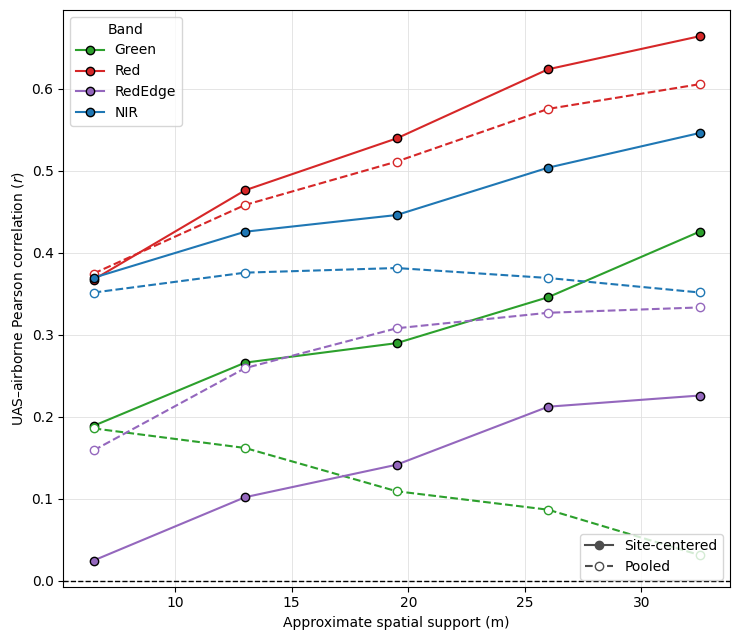

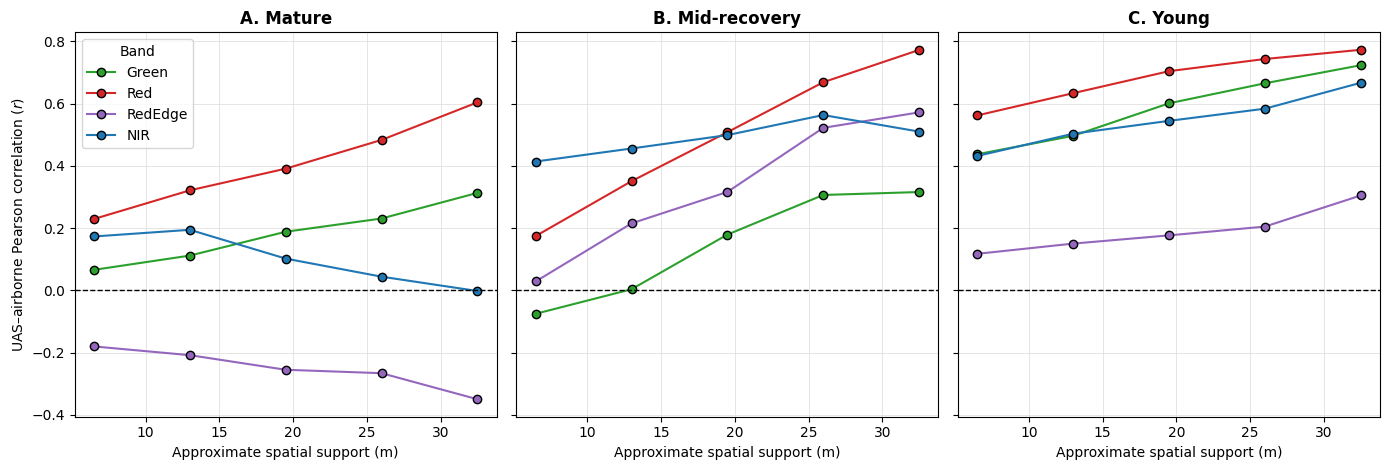

In [9]:
## B4. Plot the raw UAS–airborne scale response

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for band in ANCHOR_BANDS:
    d = overall_scale_summary[overall_scale_summary["Band"] == band].sort_values("Approx_scale_m")
    color = BAND_COLORS[band]
    ax.plot(d["Approx_scale_m"], d["Centered_r_median"], "-o", color=color, markeredgecolor="black", label=band)
    ax.plot(d["Approx_scale_m"], d["Pooled_r_median"], "--o", color=color, markerfacecolor="white")

ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Approximate spatial support (m)"); ax.set_ylabel("UAS–airborne Pearson correlation ($r$)")
ax.grid(True, color="0.88", linewidth=0.6); ax.set_axisbelow(True)
band_legend = ax.legend(title="Band", loc="upper left")
ax.add_artist(band_legend)
ax.legend(handles=[
    Line2D([0],[0], color="0.3", marker="o", label="Site-centered"),
    Line2D([0],[0], color="0.3", linestyle="--", marker="o", markerfacecolor="white", label="Pooled"),
], loc="lower right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharex=True, sharey=True)
for i, (ax, recovery_class) in enumerate(zip(axes, RECOVERY_CLASS_ORDER)):
    dclass = recovery_scale_summary[recovery_scale_summary["Recovery_class"] == recovery_class]
    for band in ANCHOR_BANDS:
        d = dclass[dclass["Band"] == band].sort_values("Approx_scale_m")
        ax.plot(d["Approx_scale_m"], d["Site_centered_r_median"], "-o", color=BAND_COLORS[band], markeredgecolor="black", label=band)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"{chr(65+i)}. {recovery_class}", fontweight="bold")
    ax.set_xlabel("Approximate spatial support (m)"); ax.grid(True, color="0.88", linewidth=0.6)
axes[0].set_ylabel("UAS–airborne Pearson correlation ($r$)"); axes[0].legend(title="Band")
plt.tight_layout()
plt.show()

In [10]:
## C1. Extract field observations and exclude field support from final harmonization training

lai_gdf = gpd.read_file(LAI_SHAPEFILE).copy()
lai_gdf['plot_id'] = lai_gdf['plot_id'].replace({'GBS17': 'GBS16N'})
if len(lai_gdf) != EXPECTED_LAI_N:
    print(f'WARNING: expected {EXPECTED_LAI_N} LAI polygons; found {len(lai_gdf)}.')

uas_plot_records = []
for site, path in UAS_FILES.items():
    with rasterio.open(path) as src:
        local = lai_gdf.to_crs(src.crs)
        for rec in local.itertuples(index=False):
            try:
                cropped, _ = raster_mask(src, [rec.geometry], crop=True, filled=False)
            except ValueError:
                continue
            means = np.asarray(cropped.mean(axis=(1, 2)), dtype=float)
            if len(means) < 4:
                continue
            if not (np.isfinite(means[:4]).all() and np.all(means[:4] > 0)):
                continue
            uas_plot_records.append({'plot_id': rec.plot_id, 'LAI_mean': float(rec.LAI_mean), 'source_site': site, 'UAS_Green': means[0], 'UAS_Red': means[1], 'UAS_RedEdge': means[2], 'UAS_NIR': means[3]})

uas_plot_df = pd.DataFrame(uas_plot_records)
duplicates = uas_plot_df.loc[uas_plot_df['plot_id'].duplicated(keep=False), 'plot_id'].unique()
if len(duplicates) > 0:
    raise RuntimeError('Plots with valid observations in more than one UAS mosaic: ' + ', '.join(map(str, duplicates)))
uas_plot_df = uas_plot_df.reset_index(drop=True)
print(f'Field plots with valid UAS MSI = {len(uas_plot_df)}')
if len(uas_plot_df) != EXPECTED_COMMON_UAS_N:
    print(f'WARNING: expected common UAS n={EXPECTED_COMMON_UAS_N}.')
display(uas_plot_df[['plot_id', 'source_site', 'LAI_mean']].sort_values('plot_id').reset_index(drop=True))

def infer_field_source_site(plot_id):
    pid = str(plot_id)
    if pid.startswith('GBS06'):
        return 'BY_2006'
    if pid == 'GBS16N':
        return 'BY_2017_16'
    if pid.startswith('GBS16'):
        return 'BY_2016'
    if pid.startswith('GBS19'):
        return 'BY_2019'
    if pid.startswith('GBS20'):
        return 'BY_2020'
    raise ValueError(f'Unrecognized field plot domain for {plot_id!r}.')

def extract_full_support_from_scene(src, scene, geom):
    rows = []
    cols = []
    spectra = []
    try:
        win = geometry_window(src, [mapping(geom)])
        data = src.read(window=win).astype(float)
        inside = geometry_mask([mapping(geom)], out_shape=(data.shape[1], data.shape[2]), transform=src.window_transform(win), invert=True, all_touched=True)
        check_index = min(100, data.shape[0] - 1)
        check = inside & np.isfinite(data[check_index]) & (data[check_index] > -50)
        rr, cc = np.where(check)
        for r_local, c_local in zip(rr, cc):
            row = int(win.row_off) + int(r_local)
            col = int(win.col_off) + int(c_local)
            spectrum = data[:, r_local, c_local].astype(float)
            spectrum[spectrum <= -50] = np.nan
            if not np.isfinite(spectrum[valid_hsi_analysis_mask]).all():
                continue
            raw_anchors = synthesize_srf_anchors(spectrum)
            if not np.isfinite(list(raw_anchors.values())).all():
                continue
            rows.append(row)
            cols.append(col)
            spectra.append(spectrum)
    except Exception:
        rows = []
        cols = []
        spectra = []
    if len(rows) == 0:
        cx = geom.centroid.x
        cy = geom.centroid.y
        row, col = src.index(cx, cy)
        if not (0 <= row < src.height and 0 <= col < src.width):
            return None
        spectrum = src.read(window=Window(col, row, 1, 1)).reshape(src.count).astype(float)
        spectrum[spectrum <= -50] = np.nan
        if not np.isfinite(spectrum[valid_hsi_analysis_mask]).all():
            return None
        raw_anchors = synthesize_srf_anchors(spectrum)
        if not np.isfinite(list(raw_anchors.values())).all():
            return None
        rows = [int(row)]
        cols = [int(col)]
        spectra = [spectrum]
    xs, ys = rasterio.transform.xy(src.transform, np.asarray(rows, dtype=int), np.asarray(cols, dtype=int), offset='center')
    support_xy = tuple(((float(x), float(y)) for x, y in zip(xs, ys)))
    support_pixel_ids = tuple((f'{scene}__{row}_{col}' for row, col in zip(rows, cols)))
    support_spectra = np.asarray(spectra, dtype=float)
    return {'support_xy': support_xy, 'support_pixel_ids': support_pixel_ids, 'support_spectra': support_spectra, 'pixels_used': len(rows), 'raw_plot_spectrum': np.nanmean(support_spectra, axis=0)}
field_candidates = {pid: [] for pid in lai_gdf['plot_id']}

for scene, path in AVIRIS_L2B.items():
    subdataset = f'NETCDF:{path}:/reflectance/reflectance'
    with rasterio.open(subdataset) as src:
        local = lai_gdf.to_crs(src.crs)
        raster_box = box(src.bounds.left, src.bounds.bottom, src.bounds.right, src.bounds.top)
        img_cx = (src.bounds.left + src.bounds.right) / 2
        img_cy = (src.bounds.bottom + src.bounds.top) / 2
        for rec in local.itertuples(index=False):
            geom = rec.geometry
            if not raster_box.intersects(geom):
                continue
            support = extract_full_support_from_scene(src, scene, geom)
            if support is None:
                continue
            field_candidates[rec.plot_id].append({'scene': scene, 'dist_to_image_center': float(np.hypot(geom.centroid.x - img_cx, geom.centroid.y - img_cy)), **support})

field_records = []
for rec in lai_gdf[['plot_id', 'LAI_mean']].itertuples(index=False):
    options = field_candidates[rec.plot_id]
    if not options:
        continue
    best = min(options, key=lambda d: d['dist_to_image_center'])
    field_records.append({'plot_id': rec.plot_id, 'LAI_mean': float(rec.LAI_mean), 'source_site': infer_field_source_site(rec.plot_id), **best})

field_air_df = pd.DataFrame(field_records).sort_values('plot_id').reset_index(drop=True)
print(f'Field plots with valid full-spectrum AVIRIS data = {len(field_air_df)}')
if len(field_air_df) != EXPECTED_LAI_N:
    raise RuntimeError(f'Expected {EXPECTED_LAI_N} AVIRIS field plots; found {len(field_air_df)}.')
display(field_air_df[['plot_id', 'LAI_mean', 'source_site', 'scene', 'pixels_used', 'dist_to_image_center']])

deployment_keep = np.ones(len(calibration_df), dtype=bool)
deployment_exclusion_rows = []
for rec in field_air_df.itertuples(index=False):
    support_xy = np.asarray(rec.support_xy, dtype=float)
    same_scene_idx = np.where(calibration_df['scene'].to_numpy() == rec.scene)[0]
    if len(same_scene_idx) == 0:
        deployment_exclusion_rows.append({'plot_id': rec.plot_id, 'scene': rec.scene, 'n_support_pixels': len(support_xy), 'n_calibration_pixels_excluded': 0})
        continue
    cal_xy = calibration_df.loc[same_scene_idx, ['x_m', 'y_m']].to_numpy(dtype=float)
    tree = cKDTree(support_xy)
    distance, _ = tree.query(cal_xy, k=1, p=np.inf)
    local_excluded_idx = same_scene_idx[distance <= FIELD_BUFFER_M + 1e-09]
    deployment_keep[local_excluded_idx] = False
    deployment_exclusion_rows.append({'plot_id': rec.plot_id, 'scene': rec.scene, 'n_support_pixels': len(support_xy), 'n_calibration_pixels_excluded': len(local_excluded_idx)})
deployment_cal_df = calibration_df.loc[deployment_keep].copy().reset_index(drop=True)

print('============================================================')
print('FINAL HSI DEPLOYMENT CALIBRATION DOMAIN')
print('============================================================')
print(f'Strict-interior calibration before field exclusion: n={len(calibration_df)}')
print(f'After union one-cell field-support exclusion: n={len(deployment_cal_df)}')
print(f'Unique calibration pixels excluded: {int((~deployment_keep).sum())}')
display(pd.DataFrame(deployment_exclusion_rows))
print('\nRemaining deployment support by site:')
display(deployment_cal_df.groupby('site').size().rename('n_train').to_frame())
if set(deployment_cal_df['site'].unique()) != set(calibration_df['site'].unique()):
    raise RuntimeError('Field-support exclusion removed an entire calibration site.')

if len(deployment_cal_df) != EXPECTED_DEPLOY_N:
    raise RuntimeError(f'Locked deployment method expects n={EXPECTED_DEPLOY_N} after field-support exclusion; found n={len(deployment_cal_df)}.')
print(f'LOCKED deployment calibration support confirmed: n={len(deployment_cal_df)}')

X_DEPLOY_ANCHOR = deployment_cal_df[ANCHOR_X_COLS].to_numpy(dtype=float)
if not np.isfinite(X_DEPLOY_ANCHOR).all():
    raise RuntimeError('Non-finite values remain in deployment anchor predictors.')
final_anchor_models = {}
for band, target_col in TARGET_MAP.items():
    y = deployment_cal_df[target_col].to_numpy(dtype=float)
    model = RandomForestRegressor(**ANCHOR_RF_KWARGS)
    model.fit(X_DEPLOY_ANCHOR, y)
    final_anchor_models[band] = model
print(f'Final four-band SRF anchor RFs trained: {list(final_anchor_models)}')

Field plots with valid UAS MSI = 11


,plot_id,source_site,LAI_mean
0,GBS0619,BY_2006,2.112576
1,GBS0622,BY_2006,2.348314
2,GBS0625,BY_2006,1.575255
3,GBS0626,BY_2006,1.790895
4,GBS0627,BY_2006,1.413221
5,GBS06P,BY_2006,1.977499
6,GBS164,BY_2016,1.737210
7,GBS16N,BY_2017_16,1.415269
8,GBS16P,BY_2016,0.704166
9,GBS19P,BY_2019,1.133654


Field plots with valid full-spectrum AVIRIS data = 20


,plot_id,LAI_mean,source_site,scene,pixels_used,dist_to_image_center
0,GBS0619,2.112576,BY_2006,ang20231031t092656_002,2,2069.789464
1,GBS0622,2.348314,BY_2006,ang20231031t092656_002,1,2032.952380
2,GBS0625,1.575255,BY_2006,ang20231031t092656_002,2,2078.138152
3,GBS0626,1.790895,BY_2006,ang20231031t092656_002,4,2004.185278
4,GBS0627,1.413221,BY_2006,ang20231031t092656_002,4,2000.436585
5,GBS06P,1.977499,BY_2006,ang20231031t092656_002,2,2099.390951
6,GBS161,1.603689,BY_2016,ang20231117t123306_001,4,956.419663
7,GBS162,2.146058,BY_2016,ang20231117t123306_001,2,1105.176524
8,GBS164,1.737210,BY_2016,ang20231117t123306_001,4,955.413203
9,GBS168,1.622965,BY_2016,ang20231117t123306_001,2,1072.729894


FINAL HSI DEPLOYMENT CALIBRATION DOMAIN
Strict-interior calibration before field exclusion: n=2147
After union one-cell field-support exclusion: n=2006
Unique calibration pixels excluded: 141


,plot_id,scene,n_support_pixels,n_calibration_pixels_excluded
0,GBS0619,ang20231031t092656_002,2,12
1,GBS0622,ang20231031t092656_002,1,9
2,GBS0625,ang20231031t092656_002,2,12
3,GBS0626,ang20231031t092656_002,4,8
4,GBS0627,ang20231031t092656_002,4,16
5,GBS06P,ang20231031t092656_002,2,12
6,GBS161,ang20231117t123306_001,4,0
7,GBS162,ang20231117t123306_001,2,0
8,GBS164,ang20231117t123306_001,4,16
9,GBS168,ang20231117t123306_001,2,3



Remaining deployment support by site:


,n_train
site,
BY_2006,486
BY_2016,423
BY_2017_16,429
BY_2019,393
BY_2020,275


LOCKED deployment calibration support confirmed: n=2006
Final four-band SRF anchor RFs trained: ['Green', 'Red', 'RedEdge', 'NIR']


In [ ]:
## C2. Build raw, band-harmonized, and direct-index-harmonized MSI representations

field_harmonized_rows = []
gain_rows = []

for rec in field_air_df.itertuples(index=False):
    support_spectra = np.asarray(rec.support_spectra, dtype=float)
    if support_spectra.ndim != 2 or support_spectra.shape[1] != len(wavelengths):
        raise RuntimeError(f'{rec.plot_id}: malformed support_spectra.')
    harmonized_support = []
    for pixel_i, spectrum in enumerate(support_spectra):
        if not np.isfinite(spectrum[valid_hsi_analysis_mask]).all():
            raise RuntimeError(f'{rec.plot_id}: non-finite field spectrum in the HSI analysis mask.')
        raw_anchors = synthesize_srf_anchors(spectrum)
        raw_anchor_predictors = np.asarray([raw_anchors[band] for band in ANCHOR_BANDS], dtype=float).reshape(1, -1)
        if not np.isfinite(raw_anchor_predictors).all():
            raise RuntimeError(f'{rec.plot_id}: invalid measured-SRF anchor predictor.')
        predicted_anchors = {band: float(model.predict(raw_anchor_predictors)[0]) for band, model in final_anchor_models.items()}
        if not np.isfinite([raw_anchors[band] for band in ANCHOR_BANDS]).all():
            raise RuntimeError(f'{rec.plot_id}: invalid raw SRF anchor.')
        solved = solve_srf_constrained_gain(spectrum, predicted_anchors)
        harmonized_spectrum = solved['harmonized_spectrum']
        knot_gains = solved['knot_gains']
        reconstructed_anchors = solved['reconstructed_anchors']
        harmonized_support.append(harmonized_spectrum)
        gain_rows.append({'plot_id': rec.plot_id, 'scene': rec.scene, 'support_pixel_index': pixel_i, 'KnotGain_Green': knot_gains[0], 'KnotGain_Red': knot_gains[1], 'KnotGain_RedEdge': knot_gains[2], 'KnotGain_NIR': knot_gains[3], 'Pred_Green': predicted_anchors['Green'], 'Pred_Red': predicted_anchors['Red'], 'Pred_RedEdge': predicted_anchors['RedEdge'], 'Pred_NIR': predicted_anchors['NIR'], 'Raw_Green': raw_anchors['Green'], 'Raw_Red': raw_anchors['Red'], 'Raw_RedEdge': raw_anchors['RedEdge'], 'Raw_NIR': raw_anchors['NIR'], 'Recon_Green': reconstructed_anchors['Green'], 'Recon_Red': reconstructed_anchors['Red'], 'Recon_RedEdge': reconstructed_anchors['RedEdge'], 'Recon_NIR': reconstructed_anchors['NIR'], 'Max_abs_anchor_residual': solved['max_abs_anchor_residual'], 'Gain_system_condition_number': solved['condition_number'], 'Gain_solver': solved['solver'], 'Min_gain_curve': float(np.nanmin(solved['gain_curve'])), 'Max_gain_curve': float(np.nanmax(solved['gain_curve']))})
    harmonized_support = np.asarray(harmonized_support, dtype=float)
    raw_plot_spectrum = np.nanmean(support_spectra, axis=0)
    harmonized_plot_spectrum = np.nanmean(harmonized_support, axis=0)
    field_harmonized_rows.append({'plot_id': rec.plot_id, 'LAI_mean': rec.LAI_mean, 'source_site': rec.source_site, 'scene': rec.scene, 'pixels_used': rec.pixels_used, 'raw_spectrum': raw_plot_spectrum, 'harmonized_spectrum': harmonized_plot_spectrum})

field_harmonized_df = pd.DataFrame(field_harmonized_rows).sort_values('plot_id').reset_index(drop=True)
field_gain_df = pd.DataFrame(gain_rows)
print(f'Field plots harmonized = {len(field_harmonized_df)}')
print('\n============================================================')
print('SRF-CONSTRAINED ANCHOR CLOSURE AUDIT')
print('============================================================')

closure_cols = ['Max_abs_anchor_residual', 'Gain_system_condition_number', 'Min_gain_curve', 'Max_gain_curve']
display(field_gain_df[closure_cols].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(8))
max_closure_error = float(field_gain_df['Max_abs_anchor_residual'].max())
print(f'\nMaximum absolute SRF-anchor closure error = {max_closure_error:.12g}')
print('Gain solvers used:')
display(field_gain_df['Gain_solver'].value_counts().rename('n').to_frame())
nonpositive_gain_pixels = int((field_gain_df['Min_gain_curve'] <= 0).sum())
print(f'Field support pixels with any non-positive gain = {nonpositive_gain_pixels}')
if max_closure_error > 1e-08:
    print('WARNING: SRF closure is not at numerical precision; inspect gain-system conditioning.')
if nonpositive_gain_pixels > 0:
    print('WARNING: at least one solved spectral gain curve becomes non-positive. Inspect those support pixels before interpretation.')
print('\nGain-knot summary:')
display(field_gain_df[['KnotGain_Green', 'KnotGain_Red', 'KnotGain_RedEdge', 'KnotGain_NIR']].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(4))
print('\nPlot-level support:')
display(field_harmonized_df[['plot_id', 'LAI_mean', 'source_site', 'scene', 'pixels_used']])

raw_spectra_n20 = np.vstack(field_harmonized_df['raw_spectrum'].to_numpy())
harm_spectra_n20 = np.vstack(field_harmonized_df['harmonized_spectrum'].to_numpy())
raw_hsi_indices_n20 = calculate_hsi_indices(raw_spectra_n20, wavelengths)
harm_hsi_indices_n20 = calculate_hsi_indices(harm_spectra_n20, wavelengths)
raw_srf_bands_n20 = synthesize_srf_anchor_matrix(raw_spectra_n20)
harm_srf_bands_n20 = synthesize_srf_anchor_matrix(harm_spectra_n20)
raw_srf_msi_indices_n20 = calculate_uas_indices(raw_srf_bands_n20['Green'], raw_srf_bands_n20['Red'], raw_srf_bands_n20['RedEdge'], raw_srf_bands_n20['NIR'])
harm_srf_msi_indices_n20 = calculate_uas_indices(harm_srf_bands_n20['Green'], harm_srf_bands_n20['Red'], harm_srf_bands_n20['RedEdge'], harm_srf_bands_n20['NIR'])
y_n20 = field_harmonized_df['LAI_mean'].to_numpy(dtype=float)
plot_ids_n20 = field_harmonized_df['plot_id'].astype(str).to_numpy()

print(f'Native HSI n=20 representations: {len(raw_hsi_indices_n20)} raw indices and {len(harm_hsi_indices_n20)} harmonized indices.')
print(f'SRF-MSI bridge representations: {len(raw_srf_msi_indices_n20)} raw indices and {len(harm_srf_msi_indices_n20)} harmonized indices.')

pred_anchor_means = field_gain_df.groupby('plot_id', as_index=True)[['Pred_Green', 'Pred_Red', 'Pred_RedEdge', 'Pred_NIR']].mean()
plot_closure_rows = []
for i, pid in enumerate(plot_ids_n20):
    pid = str(pid)
    row = {'plot_id': pid}
    for band in ANCHOR_BANDS:
        predicted_mean = float(pred_anchor_means.loc[pid, f'Pred_{band}'])
        reconstructed_plot = float(harm_srf_bands_n20[band][i])
        row[f'Residual_{band}'] = reconstructed_plot - predicted_mean
    row['Max_abs_plot_anchor_residual'] = max((abs(row[f'Residual_{band}']) for band in ANCHOR_BANDS))
    plot_closure_rows.append(row)
plot_srf_closure = pd.DataFrame(plot_closure_rows)
print('\nPlot-level SRF closure:')
display(plot_srf_closure.round(10))
print(f"\nMaximum plot-level SRF closure error = {plot_srf_closure['Max_abs_plot_anchor_residual'].max():.12g}")

common_n11 = uas_plot_df.merge(field_harmonized_df[['plot_id', 'LAI_mean', 'source_site', 'scene', 'pixels_used']], on='plot_id', how='inner', validate='one_to_one', suffixes=('_UAS', '_HSI')).sort_values('plot_id').reset_index(drop=True)
if not np.allclose(common_n11['LAI_mean_UAS'].to_numpy(dtype=float), common_n11['LAI_mean_HSI'].to_numpy(dtype=float), rtol=0, atol=1e-12):
    raise RuntimeError('LAI values differ between UAS and HSI field tables.')
common_n11['LAI_mean'] = common_n11['LAI_mean_UAS'].astype(float)
if len(common_n11) != EXPECTED_COMMON_UAS_N:
    raise RuntimeError(f'Expected common n={EXPECTED_COMMON_UAS_N}; found {len(common_n11)}.')
field_lookup = {pid: i for i, pid in enumerate(field_harmonized_df['plot_id'].astype(str))}
common_pos = np.array([field_lookup[str(pid)] for pid in common_n11['plot_id']], dtype=int)
uas_indices_n11 = calculate_uas_indices(common_n11['UAS_Green'], common_n11['UAS_Red'], common_n11['UAS_RedEdge'], common_n11['UAS_NIR'])
raw_hsi_indices_n11 = calculate_hsi_indices(raw_spectra_n20[common_pos], wavelengths)
harm_hsi_indices_n11 = calculate_hsi_indices(harm_spectra_n20[common_pos], wavelengths)
raw_srf_msi_indices_n11 = {name: np.asarray(values, dtype=float)[common_pos] for name, values in raw_srf_msi_indices_n20.items()}
harm_srf_msi_indices_n11 = {name: np.asarray(values, dtype=float)[common_pos] for name, values in harm_srf_msi_indices_n20.items()}
y_n11 = common_n11['LAI_mean'].to_numpy(dtype=float)
print('Common UAS + HSI plots:')
display(common_n11[['plot_id', 'LAI_mean', 'source_site_UAS', 'source_site_HSI', 'scene', 'pixels_used']])

X_DEPLOY = deployment_cal_df[ANCHOR_X_COLS].to_numpy(float)
deploy_uas_indices = calculate_uas_indices(deployment_cal_df['UAS_Green'], deployment_cal_df['UAS_Red'], deployment_cal_df['UAS_RedEdge'], deployment_cal_df['UAS_NIR'])
final_direct_index_models = {}
for index_name in MSI_INDEX_NAMES:
    y_target = np.asarray(deploy_uas_indices[index_name], dtype=float)
    valid = np.isfinite(X_DEPLOY).all(axis=1) & np.isfinite(y_target)
    model = RandomForestRegressor(**ANCHOR_RF_KWARGS)
    model.fit(X_DEPLOY[valid], y_target[valid])
    final_direct_index_models[index_name] = model

direct_field_rows = []
for rec in field_air_df.itertuples(index=False):
    support_spectra = np.asarray(rec.support_spectra, dtype=float)
    support_bands = synthesize_srf_anchor_matrix(support_spectra)
    X_support = np.column_stack([support_bands[b] for b in ANCHOR_BANDS])
    row = {'plot_id': rec.plot_id}
    for index_name, model in final_direct_index_models.items():
        row[f'Direct_{index_name}'] = float(np.mean(model.predict(X_support)))
    direct_field_rows.append(row)
    
direct_field_df = pd.DataFrame(direct_field_rows)
field_revision_df = field_harmonized_df.merge(direct_field_df, on='plot_id', how='left', validate='one_to_one').sort_values('plot_id').reset_index(drop=True)
raw_msi_indices_n20 = raw_srf_msi_indices_n20
band_harmonized_msi_indices_n20 = harm_srf_msi_indices_n20
direct_harmonized_msi_indices_n20 = {name: field_revision_df[f'Direct_{name}'].to_numpy(float) for name in MSI_INDEX_NAMES}
print(f'MSI branch ready: {len(MSI_INDEX_NAMES)} indices; field n={len(field_revision_df)}.')

Field plots harmonized = 20

SRF-CONSTRAINED ANCHOR CLOSURE AUDIT


,Max_abs_anchor_residual,Gain_system_condition_number,Min_gain_curve,Max_gain_curve
count,54.0,54.000000,54.000000,54.000000
mean,0.0,5.214564,0.590013,1.025558
std,0.0,0.893418,0.047737,0.078021
min,0.0,3.934785,0.465023,0.909672
5%,0.0,4.036330,0.504107,0.913888
25%,0.0,4.591651,0.556881,0.945931
50%,0.0,4.895095,0.603610,1.030363
75%,0.0,5.844968,0.629393,1.088817
95%,0.0,6.934232,0.642378,1.137346
max,0.0,7.383597,0.650816,1.159767



Maximum absolute SRF-anchor closure error = 8.32667268469e-17
Gain solvers used:


,n
Gain_solver,
solve,54


Field support pixels with any non-positive gain = 0

Gain-knot summary:


...

Native HSI n=20 representations: 28 raw indices and 28 harmonized indices.
SRF-MSI bridge representations: 17 raw indices and 17 harmonized indices.

Plot-level SRF closure:


,plot_id,Residual_Green,Residual_Red,Residual_RedEdge,Residual_NIR,Max_abs_plot_anchor_residual
0,GBS0619,0.0,0.0,-0.0,0.0,0.0
1,GBS0622,0.0,-0.0,0.0,0.0,0.0
2,GBS0625,-0.0,-0.0,-0.0,0.0,0.0
3,GBS0626,0.0,0.0,-0.0,-0.0,0.0
4,GBS0627,0.0,0.0,0.0,0.0,0.0
5,GBS06P,-0.0,0.0,0.0,0.0,0.0
6,GBS161,0.0,0.0,0.0,0.0,0.0
7,GBS162,-0.0,0.0,0.0,0.0,0.0
8,GBS164,0.0,0.0,0.0,-0.0,0.0
9,GBS168,0.0,0.0,-0.0,0.0,0.0



Maximum plot-level SRF closure error = 5.55111512313e-17
Common UAS + HSI plots:


,plot_id,LAI_mean,source_site_UAS,source_site_HSI,scene,pixels_used
0,GBS0619,2.112576,BY_2006,BY_2006,ang20231031t092656_002,2
1,GBS0622,2.348314,BY_2006,BY_2006,ang20231031t092656_002,1
2,GBS0625,1.575255,BY_2006,BY_2006,ang20231031t092656_002,2
3,GBS0626,1.790895,BY_2006,BY_2006,ang20231031t092656_002,4
4,GBS0627,1.413221,BY_2006,BY_2006,ang20231031t092656_002,4
5,GBS06P,1.977499,BY_2006,BY_2006,ang20231031t092656_002,2
6,GBS164,1.737210,BY_2016,BY_2016,ang20231117t123306_001,4
7,GBS16N,1.415269,BY_2017_16,BY_2017_16,ang20231117t123306_001,1
8,GBS16P,0.704166,BY_2016,BY_2016,ang20231117t123306_001,4
9,GBS19P,1.133654,BY_2019,BY_2019,ang20231117t123306_001,4


MSI branch ready: 17 indices; field n=20.


In [12]:
## C3. Screen single-index MSI models and run paired common-sample inference

def screen_msi_models(approach_dict, y):
    rows = []
    store = {}
    for approach, idx_dict in approach_dict.items():
        for index_name, values in idx_dict.items():
            for form in ['Linear', 'Quadratic']:
                result = evaluate_single_index(values, y, form)
                rows.append({'Approach': approach, 'Index': index_name, 'Form': form, 'n': result['n'], 'Full_R2': result['Full_R2'], 'Full_RMSE': result['Full_RMSE'], 'LOOCV_R2': result['LOOCV_R2'], 'LOOCV_RMSE': result['LOOCV_RMSE'], 'LOOCV_MAE': result['LOOCV_MAE']})
                store[approach, index_name, form] = result
    return (pd.DataFrame(rows), store)

msi_approaches_n20 = {'Raw airborne MSI': raw_msi_indices_n20, 'Band-harmonized MSI': band_harmonized_msi_indices_n20, 'Direct-index-harmonized MSI': direct_harmonized_msi_indices_n20}
msi_results_n20, msi_store_n20 = screen_msi_models(msi_approaches_n20, y_n20)

print('MSI n=20 best models (descriptive best-of-many):')
display(msi_results_n20.sort_values(['Approach', 'LOOCV_R2'], ascending=[True, False]).groupby('Approach', as_index=False).first().round(3))
raw_tbl = msi_results_n20[msi_results_n20['Approach'] == 'Raw airborne MSI']
band_tbl = msi_results_n20[msi_results_n20['Approach'] == 'Band-harmonized MSI']
direct_tbl = msi_results_n20[msi_results_n20['Approach'] == 'Direct-index-harmonized MSI']
msi_matched_n20 = raw_tbl[['Index', 'Form', 'LOOCV_R2', 'LOOCV_RMSE']].rename(columns={'LOOCV_R2': 'Raw_R2', 'LOOCV_RMSE': 'Raw_RMSE'}).merge(band_tbl[['Index', 'Form', 'LOOCV_R2', 'LOOCV_RMSE']].rename(columns={'LOOCV_R2': 'BandH_R2', 'LOOCV_RMSE': 'BandH_RMSE'}), on=['Index', 'Form'], validate='one_to_one').merge(direct_tbl[['Index', 'Form', 'LOOCV_R2', 'LOOCV_RMSE']].rename(columns={'LOOCV_R2': 'DirectH_R2', 'LOOCV_RMSE': 'DirectH_RMSE'}), on=['Index', 'Form'], validate='one_to_one')
msi_matched_n20['BandH_Delta_R2'] = msi_matched_n20['BandH_R2'] - msi_matched_n20['Raw_R2']
msi_matched_n20['DirectH_Delta_R2'] = msi_matched_n20['DirectH_R2'] - msi_matched_n20['Raw_R2']
msi_matched_n20['BandH_RMSE_reduction'] = msi_matched_n20['Raw_RMSE'] - msi_matched_n20['BandH_RMSE']
msi_matched_n20['DirectH_RMSE_reduction'] = msi_matched_n20['Raw_RMSE'] - msi_matched_n20['DirectH_RMSE']

print('\nMSI n=20 matched-index/form effects:')
display(msi_matched_n20.sort_values('BandH_Delta_R2', ascending=False).round(3))
common_direct = common_n11[['plot_id']].merge(field_revision_df[['plot_id'] + [f'Direct_{x}' for x in MSI_INDEX_NAMES]], on='plot_id', how='left', validate='one_to_one')
direct_msi_indices_n11 = {name: common_direct[f'Direct_{name}'].to_numpy(float) for name in MSI_INDEX_NAMES}
msi_common_approaches = {'UAS': uas_indices_n11, 'Raw airborne MSI': raw_srf_msi_indices_n11, 'Band-harmonized MSI': harm_srf_msi_indices_n11, 'Direct-index-harmonized MSI': direct_msi_indices_n11}
msi_results_n11, msi_store_n11 = screen_msi_models(msi_common_approaches, y_n11)
print('\nCommon n=11 best models (descriptive):')
display(msi_results_n11.sort_values(['Approach', 'LOOCV_R2'], ascending=[True, False]).groupby('Approach', as_index=False).first().round(3))
fixed_msi_n11 = msi_results_n11[(msi_results_n11['Index'] == FIXED_UAS_TRANSFER_INDEX) & (msi_results_n11['Form'] == FIXED_UAS_TRANSFER_FORM)].copy()
print(f'\nFixed common-n=11 comparison: {FIXED_UAS_TRANSFER_INDEX} ({FIXED_UAS_TRANSFER_FORM})')
display(fixed_msi_n11.round(3))

def strict_uas_coefficient_transfer(y, uas_x, candidate_dict, form='Quadratic'):
    y = np.asarray(y, float)
    uas_x = np.asarray(uas_x, float)
    loo = LeaveOneOut()
    pred = {name: np.full(len(y), np.nan, float) for name in candidate_dict}
    for tr, te in loo.split(y):
        degree = 1 if form == 'Linear' else 2
        coef = np.polyfit(uas_x[tr], y[tr], degree)
        for name, values in candidate_dict.items():
            x = np.asarray(values, float)
            pred[name][te] = np.polyval(coef, x[te])
    rows = []
    for name, p in pred.items():
        rows.append({'Representation': name, 'n': len(y), 'R2': r2_score(y, p), 'RMSE': np.sqrt(mean_squared_error(y, p)), 'MAE': mean_absolute_error(y, p)})
    return (pd.DataFrame(rows), pred)
fixed_idx = FIXED_UAS_TRANSFER_INDEX
strict_candidates = {'UAS': uas_indices_n11[fixed_idx], 'Raw airborne MSI': raw_srf_msi_indices_n11[fixed_idx], 'Band-harmonized MSI': harm_srf_msi_indices_n11[fixed_idx], 'Direct-index-harmonized MSI': direct_msi_indices_n11[fixed_idx]}
strict_transfer_results, strict_transfer_predictions = strict_uas_coefficient_transfer(y_n11, uas_indices_n11[fixed_idx], strict_candidates, FIXED_UAS_TRANSFER_FORM)
print('\nSTRICT UAS-model transfer: each fold is fitted only on UAS GDVI from the other 10 plots; the same coefficients are applied to each held-out sensor representation without airborne refitting.')
display(strict_transfer_results.round(3))

def paired_error_bootstrap(y, pred_ref, pred_candidate, n_boot=20000, random_state=42):
    y = np.asarray(y, float)
    a = np.asarray(pred_ref, float)
    b = np.asarray(pred_candidate, float)
    valid = np.isfinite(y) & np.isfinite(a) & np.isfinite(b)
    y, a, b = (y[valid], a[valid], b[valid])
    observed = np.sqrt(np.mean((y - a) ** 2)) - np.sqrt(np.mean((y - b) ** 2))
    rng = np.random.default_rng(random_state)
    boot = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(y), size=len(y))
        boot[i] = np.sqrt(np.mean((y[idx] - a[idx]) ** 2)) - np.sqrt(np.mean((y[idx] - b[idx]) ** 2))
    lo, med, hi = np.percentile(boot, [2.5, 50, 97.5])
    return {'Observed_RMSE_reduction': observed, 'Bootstrap_median': med, 'CI_2.5': lo, 'CI_97.5': hi, 'Fraction_candidate_better': float(np.mean(boot > 0))}

def paired_signflip_test(y, pred_ref, pred_candidate, loss='squared', n_mc=200000, random_state=42):
    y = np.asarray(y, float)
    a = np.asarray(pred_ref, float)
    b = np.asarray(pred_candidate, float)
    valid = np.isfinite(y) & np.isfinite(a) & np.isfinite(b)
    y, a, b = (y[valid], a[valid], b[valid])
    if loss == 'absolute':
        d = np.abs(y - a) - np.abs(y - b)
    else:
        d = (y - a) ** 2 - (y - b) ** 2
    observed = float(np.mean(d))
    n = len(d)
    if n <= 16:
        signs = np.array(list(product([-1.0, 1.0], repeat=n)))
        null = (signs * d).mean(axis=1)
    else:
        rng = np.random.default_rng(random_state)
        signs = rng.choice([-1.0, 1.0], size=(n_mc, n))
        null = (signs * d).mean(axis=1)
    p_one = (np.sum(null >= observed) + 1) / (len(null) + 1)
    p_two = (np.sum(np.abs(null) >= abs(observed)) + 1) / (len(null) + 1)
    return {'Mean_reference_minus_candidate_loss': observed, 'p_one_sided_candidate_better': p_one, 'p_two_sided': p_two}
strict_test_rows = []
ref_pred = strict_transfer_predictions['Raw airborne MSI']
for candidate in ['Band-harmonized MSI', 'Direct-index-harmonized MSI']:
    cand_pred = strict_transfer_predictions[candidate]
    strict_test_rows.append({'Comparison': f'Raw -> {candidate}', **paired_error_bootstrap(y_n11, ref_pred, cand_pred), **paired_signflip_test(y_n11, ref_pred, cand_pred, loss='squared')})
strict_transfer_inference = pd.DataFrame(strict_test_rows)
print('Paired uncertainty for strict UAS-model transfer:')
display(strict_transfer_inference.round(4))

FIXED_INDEX = 'GDVI'
FIXED_FORM = 'Quadratic'
raw_fixed = msi_store_n11['Raw airborne MSI', FIXED_INDEX, FIXED_FORM]
band_fixed = msi_store_n11['Band-harmonized MSI', FIXED_INDEX, FIXED_FORM]
direct_fixed = msi_store_n11['Direct-index-harmonized MSI', FIXED_INDEX, FIXED_FORM]
raw_pred = np.asarray(raw_fixed['LOOCV_pred'], float)
band_pred = np.asarray(band_fixed['LOOCV_pred'], float)
direct_pred = np.asarray(direct_fixed['LOOCV_pred'], float)
paired_gdvi_rows = []
for label, candidate_result, candidate_pred in [('Raw -> Band-harmonized MSI', band_fixed, band_pred), ('Raw -> Direct-index-harmonized MSI', direct_fixed, direct_pred)]:
    bootstrap = paired_error_bootstrap(y_n11, raw_pred, candidate_pred, n_boot=20000, random_state=42)
    signflip = paired_signflip_test(y_n11, raw_pred, candidate_pred, loss='squared', random_state=42)
    paired_gdvi_rows.append({'Comparison': label, 'Raw_LOOCV_R2': raw_fixed['LOOCV_R2'], 'Candidate_LOOCV_R2': candidate_result['LOOCV_R2'], 'Delta_LOOCV_R2': candidate_result['LOOCV_R2'] - raw_fixed['LOOCV_R2'], 'Raw_LOOCV_RMSE': raw_fixed['LOOCV_RMSE'], 'Candidate_LOOCV_RMSE': candidate_result['LOOCV_RMSE'], **bootstrap, 'Mean_reference_minus_candidate_loss': signflip['Mean_reference_minus_candidate_loss'], 'p_one_sided_candidate_better': signflip['p_one_sided_candidate_better'], 'p_two_sided': signflip['p_two_sided']})
paired_gdvi_inference = pd.DataFrame(paired_gdvi_rows)

print('Paired inference for fixed common-n=11 GDVI quadratic models:')
display(paired_gdvi_inference.round(4))

MSI n=20 best models (descriptive best-of-many):


,Approach,Index,Form,n,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,Band-harmonized MSI,GDVI,Linear,20,0.294,0.431,0.123,0.481,0.330
1,Direct-index-harmonized MSI,OSAVI,Linear,20,0.348,0.414,0.172,0.467,0.327
2,Raw airborne MSI,GDVI,Linear,20,0.168,0.468,-0.051,0.526,0.429



MSI n=20 matched-index/form effects:


,Index,Form,Raw_R2,Raw_RMSE,BandH_R2,BandH_RMSE,DirectH_R2,DirectH_RMSE,BandH_Delta_R2,DirectH_Delta_R2,BandH_RMSE_reduction,DirectH_RMSE_reduction
9,GDVI,Quadratic,-0.959,0.718,0.029,0.506,0.110,0.484,0.987,1.069,0.212,0.234
13,GSAVI,Quadratic,-0.974,0.721,-0.040,0.523,0.033,0.505,0.935,1.007,0.198,0.216
11,SAVI,Quadratic,-0.920,0.711,-0.203,0.563,-0.217,0.566,0.717,0.703,0.148,0.145
29,EVI2,Quadratic,-0.869,0.702,-0.159,0.553,-0.207,0.564,0.710,0.662,0.149,0.138
17,MSAVI2,Quadratic,-0.822,0.693,-0.131,0.546,-0.123,0.544,0.691,0.700,0.147,0.149
31,NIRv,Quadratic,-0.787,0.686,-0.142,0.549,-0.132,0.546,0.645,0.655,0.138,0.140
19,NDRE,Quadratic,-0.674,0.664,-0.106,0.540,-0.108,0.540,0.568,0.566,0.124,0.124
1,NDVI,Quadratic,-1.063,0.737,-0.549,0.639,-0.720,0.673,0.514,0.343,0.098,0.064
7,GRVI,Quadratic,-0.519,0.633,-0.086,0.535,0.043,0.502,0.433,0.562,0.098,0.130
15,OSAVI,Quadratic,-0.965,0.720,-0.535,0.636,-0.771,0.683,0.430,0.194,0.084,0.037



Common n=11 best models (descriptive):


...

,Representation,n,R2,RMSE,MAE
0,UAS,11,0.444,0.346,0.283
1,Raw airborne MSI,11,0.279,0.394,0.332
2,Band-harmonized MSI,11,-0.200,0.508,0.430
3,Direct-index-harmonized MSI,11,-0.173,0.503,0.425


Paired uncertainty for strict UAS-model transfer:


,Comparison,Observed_RMSE_reduction,Bootstrap_median,CI_2.5,CI_97.5,Fraction_candidate_better,Mean_reference_minus_candidate_loss,p_one_sided_candidate_better,p_two_sided
0,Raw -> Band-harmonized MSI,-0.1142,-0.1141,-0.3237,0.1085,0.1621,-0.1031,0.8194,0.3626
1,Raw -> Direct-index-harmonized MSI,-0.1085,-0.1086,-0.3182,0.1150,0.1756,-0.0973,0.8072,0.3870


Paired inference for fixed common-n=11 GDVI quadratic models:


,Comparison,Raw_LOOCV_R2,Candidate_LOOCV_R2,Delta_LOOCV_R2,Raw_LOOCV_RMSE,Candidate_LOOCV_RMSE,Observed_RMSE_reduction,Bootstrap_median,CI_2.5,CI_97.5,Fraction_candidate_better,Mean_reference_minus_candidate_loss,p_one_sided_candidate_better,p_two_sided
0,Raw -> Band-harmonized MSI,0.249,0.5617,0.3126,0.4023,0.3074,0.0949,0.0935,-0.0243,0.2066,0.9406,0.0674,0.0869,0.1733
1,Raw -> Direct-index-harmonized MSI,0.249,0.5894,0.3404,0.4023,0.2975,0.1048,0.1028,-0.0029,0.2098,0.9714,0.0734,0.0566,0.1127


RAW AIRBORNE MSI CORRELATIONS WITH LAI — n=20


,Predictor,n,r,p
0,RedEdge,20,0.526,0.017
1,NIR,20,0.468,0.037
2,GRVI,20,0.415,0.069
3,GDVI,20,0.410,0.073
4,MSAVI2,20,0.395,0.085
5,NIRv,20,0.394,0.085
6,EVI2,20,0.391,0.088
7,MTVI2,20,0.390,0.089
8,SAVI,20,0.388,0.091
9,GSAVI,20,0.373,0.105



RAW AIRBORNE MSI CORRELATIONS WITH LAI — common n=11


,Predictor,n,r,p
0,GRVI,11,0.725,0.012
1,RedEdge,11,0.704,0.016
2,NIR,11,0.691,0.018
3,MTVI2,11,0.642,0.033
4,SAVI,11,0.638,0.035
5,EVI2,11,0.638,0.035
6,MSAVI2,11,0.638,0.035
7,NIRv,11,0.633,0.036
8,GDVI,11,0.627,0.039
9,OSAVI,11,0.597,0.052



RAW AIRBORNE MSI CORRELATION COMPARISON


,Predictor,n_20,r_20,p_20,n_11,r_11,p_11
0,MTCI,20,-0.126,0.596,11,-0.384,0.244
1,Red,20,-0.058,0.808,11,0.038,0.912
2,NDRE,20,0.187,0.429,11,0.303,0.366
3,SR_RE,20,0.190,0.423,11,0.296,0.377
4,CI_RE,20,0.190,0.423,11,0.296,0.377
5,GNDVI,20,0.198,0.402,11,0.246,0.466
6,Green,20,0.234,0.320,11,0.538,0.088
7,NDVI,20,0.280,0.232,11,0.477,0.138
8,MSR,20,0.289,0.217,11,0.430,0.186
9,SR,20,0.293,0.210,11,0.409,0.211


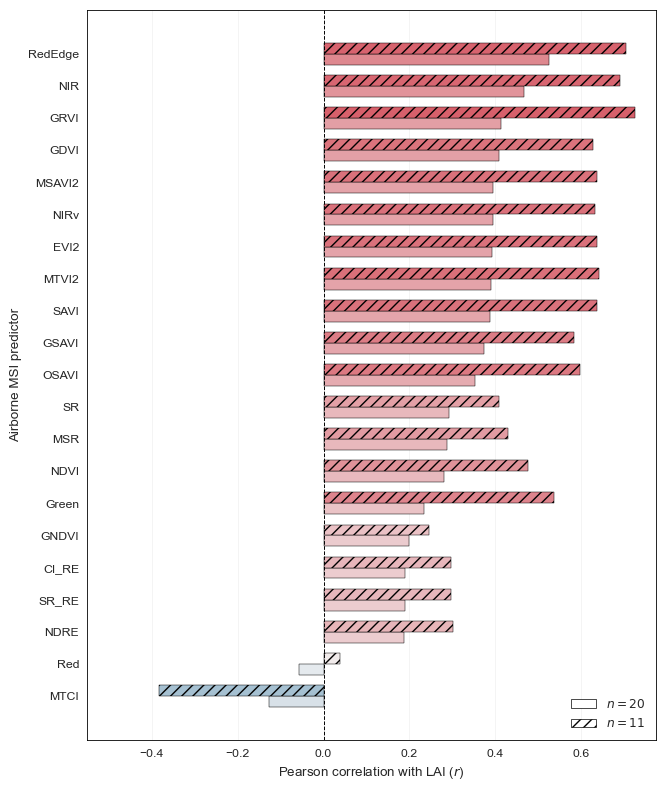


RAW AIRBORNE MSI VEGETATION-INDEX LAI MODELS — n=20
Best linear/quadratic form retained for each index (descriptive full-airborne screening).


,Index,Form,n,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,GDVI,Linear,20,0.168,0.468,-0.051,0.526,0.429
1,NIRv,Linear,20,0.155,0.472,-0.074,0.532,0.434
2,MSAVI2,Linear,20,0.156,0.472,-0.074,0.532,0.434
3,EVI2,Linear,20,0.153,0.472,-0.079,0.533,0.436
4,MTVI2,Linear,20,0.152,0.473,-0.082,0.534,0.435
5,SAVI,Linear,20,0.150,0.473,-0.084,0.534,0.437
6,GRVI,Linear,20,0.172,0.467,-0.085,0.535,0.415
7,GSAVI,Linear,20,0.139,0.476,-0.090,0.536,0.444
8,OSAVI,Linear,20,0.125,0.480,-0.119,0.543,0.448
9,SR,Linear,20,0.086,0.491,-0.149,0.550,0.457



RAW AIRBORNE MSI VEGETATION-INDEX LAI MODELS — COMMON n=11
Same field plots used in the UAS MSI analysis.


,Index,Form,n,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,GRVI,Quadratic,11,0.672,0.266,0.429,0.351,0.319
1,NIRv,Quadratic,11,0.561,0.307,0.261,0.399,0.365
2,GDVI,Quadratic,11,0.528,0.319,0.249,0.402,0.372
3,MSAVI2,Quadratic,11,0.560,0.308,0.241,0.405,0.371
4,EVI2,Quadratic,11,0.557,0.309,0.234,0.406,0.372
5,SAVI,Quadratic,11,0.553,0.310,0.219,0.410,0.376
6,MTVI2,Quadratic,11,0.585,0.299,0.171,0.423,0.381
7,OSAVI,Quadratic,11,0.530,0.318,0.161,0.425,0.375
8,GSAVI,Quadratic,11,0.490,0.332,0.152,0.427,0.399
9,MSR,Quadratic,11,0.445,0.346,0.151,0.428,0.380



COMMON n=11: UAS vs RAW AIRBORNE MSI
Same plots + same index + UAS-selected functional form


...

,Index,Form,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,GDVI,Linear,0.168,0.468,-0.051,0.526,0.429
1,NIRv,Linear,0.155,0.472,-0.074,0.532,0.434
2,MSAVI2,Linear,0.156,0.472,-0.074,0.532,0.434
3,EVI2,Linear,0.153,0.472,-0.079,0.533,0.436
4,MTVI2,Linear,0.152,0.473,-0.082,0.534,0.435
5,SAVI,Linear,0.150,0.473,-0.084,0.534,0.437
6,GRVI,Linear,0.172,0.467,-0.085,0.535,0.415
7,GSAVI,Linear,0.139,0.476,-0.090,0.536,0.444
8,OSAVI,Linear,0.125,0.480,-0.119,0.543,0.448
9,SR,Linear,0.086,0.491,-0.149,0.550,0.457



TOP 10 RAW AIRBORNE MODELS — COMMON n=11


,Index,Form,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,GRVI,Quadratic,0.672,0.266,0.429,0.351,0.319
1,NIRv,Quadratic,0.561,0.307,0.261,0.399,0.365
2,GDVI,Quadratic,0.528,0.319,0.249,0.402,0.372
3,MSAVI2,Quadratic,0.560,0.308,0.241,0.405,0.371
4,EVI2,Quadratic,0.557,0.309,0.234,0.406,0.372
5,SAVI,Quadratic,0.553,0.310,0.219,0.410,0.376
6,MTVI2,Quadratic,0.585,0.299,0.171,0.423,0.381
7,OSAVI,Quadratic,0.530,0.318,0.161,0.425,0.375
8,GSAVI,Quadratic,0.490,0.332,0.152,0.427,0.399
9,MSR,Quadratic,0.445,0.346,0.151,0.428,0.380



BEST n=20 MSI MODEL BY REPRESENTATION (DESCRIPTIVE SCREENING ONLY)


,Approach,Index,Form,n,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,Band-harmonized MSI,GDVI,Linear,20,0.294,0.431,0.123,0.481,0.330
1,Direct-index-harmonized MSI,OSAVI,Linear,20,0.348,0.414,0.172,0.467,0.327
2,Raw airborne MSI,GDVI,Linear,20,0.168,0.468,-0.051,0.526,0.429


In [13]:
## C4. Raw airborne MSI results

sns.set_theme(context='paper', style='white', font='Arial', rc={'axes.edgecolor': 'black', 'axes.linewidth': 0.6, 'grid.color': '0.88', 'grid.linewidth': 0.4})
bar_palette = sns.diverging_palette(240, 10, s=85, l=45, n=256)

def get_corr_colors(values):
    return [bar_palette[int(np.clip((r + 1) / 2 * 255, 0, 255))] for r in values]
raw_airborne_band_dict_n20 = {'Green': np.asarray(raw_srf_bands_n20['Green'], float), 'Red': np.asarray(raw_srf_bands_n20['Red'], float), 'RedEdge': np.asarray(raw_srf_bands_n20['RedEdge'], float), 'NIR': np.asarray(raw_srf_bands_n20['NIR'], float)}
raw_airborne_predictors_n20 = {**raw_airborne_band_dict_n20, **raw_msi_indices_n20}

corr_rows_n20 = []
for name, values in raw_airborne_predictors_n20.items():
    values = np.asarray(values, float)
    valid = np.isfinite(values) & np.isfinite(y_n20)
    r, p = pearsonr(values[valid], y_n20[valid])
    corr_rows_n20.append({'Predictor': name, 'n': int(valid.sum()), 'r': r, 'p': p})
raw_airborne_correlation_n20 = pd.DataFrame(corr_rows_n20).sort_values('r', key=lambda x: np.abs(x), ascending=False).reset_index(drop=True)

print('RAW AIRBORNE MSI CORRELATIONS WITH LAI — n=20')
display(raw_airborne_correlation_n20.round(3))
raw_airborne_band_dict_n11 = {'Green': np.asarray(raw_srf_bands_n20['Green'], float)[common_pos], 'Red': np.asarray(raw_srf_bands_n20['Red'], float)[common_pos], 'RedEdge': np.asarray(raw_srf_bands_n20['RedEdge'], float)[common_pos], 'NIR': np.asarray(raw_srf_bands_n20['NIR'], float)[common_pos]}
raw_airborne_predictors_n11 = {**raw_airborne_band_dict_n11, **raw_srf_msi_indices_n11}
corr_rows_n11 = []
for name, values in raw_airborne_predictors_n11.items():
    values = np.asarray(values, float)
    valid = np.isfinite(values) & np.isfinite(y_n11)
    r, p = pearsonr(values[valid], y_n11[valid])
    corr_rows_n11.append({'Predictor': name, 'n': int(valid.sum()), 'r': r, 'p': p})
raw_airborne_correlation_n11 = pd.DataFrame(corr_rows_n11).sort_values('r', key=lambda x: np.abs(x), ascending=False).reset_index(drop=True)

print('\nRAW AIRBORNE MSI CORRELATIONS WITH LAI — common n=11')
display(raw_airborne_correlation_n11.round(3))
raw_airborne_correlation_table = raw_airborne_correlation_n20[['Predictor', 'n', 'r', 'p']].rename(columns={'n': 'n_20', 'r': 'r_20', 'p': 'p_20'}).merge(raw_airborne_correlation_n11[['Predictor', 'n', 'r', 'p']].rename(columns={'n': 'n_11', 'r': 'r_11', 'p': 'p_11'}), on='Predictor', how='inner', validate='one_to_one')
raw_airborne_correlation_table = raw_airborne_correlation_table.sort_values('r_20', ascending=True).reset_index(drop=True)

print('\nRAW AIRBORNE MSI CORRELATION COMPARISON')
display(raw_airborne_correlation_table.round(3))
plot_df = raw_airborne_correlation_table.copy()
y_pos = np.arange(len(plot_df))
bar_height = 0.34
colors_n20 = get_corr_colors(plot_df['r_20'].values)
colors_n11 = get_corr_colors(plot_df['r_11'].values)
fig, ax = plt.subplots(figsize=(6.75, 8.0))
ax.barh(y_pos - bar_height / 2, plot_df['r_20'], height=bar_height, color=colors_n20, edgecolor='black', linewidth=0.35, zorder=2)
ax.barh(y_pos + bar_height / 2, plot_df['r_11'], height=bar_height, color=colors_n11, edgecolor='black', linewidth=0.35, hatch='///', zorder=2)
ax.axvline(0, color='black', linestyle='--', linewidth=0.7, zorder=3)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['Predictor'])
ax.set_xlabel('Pearson correlation with LAI ($r$)')
ax.set_ylabel('Airborne MSI predictor')
all_r = np.concatenate([plot_df['r_20'].to_numpy(float), plot_df['r_11'].to_numpy(float)])
x_min = min(-0.55, np.nanmin(all_r) - 0.05)
x_max = max(0.55, np.nanmax(all_r) + 0.05)
ax.set_xlim(x_min, x_max)
ax.grid(axis='x', linestyle='-', linewidth=0.4, alpha=0.6)
ax.grid(axis='y', visible=False)
ax.set_axisbelow(True)
ax.tick_params(axis='both', length=2.5, width=0.6)
for spine in ax.spines.values():
    spine.set_linewidth(0.6)
legend_handles = [Patch(facecolor='white', edgecolor='black', linewidth=0.5, label='$n=20$'), Patch(facecolor='white', edgecolor='black', linewidth=0.5, hatch='///', label='$n=11$')]
ax.legend(handles=legend_handles, loc='lower right', frameon=False)
plt.tight_layout()
plt.show()

def best_form_by_index(results_df, approach):
    """
    Retain the better Linear/Quadratic model for each index,
    ranked primarily by LOOCV R2 and secondarily by LOOCV RMSE.
    """
    return results_df[results_df['Approach'] == approach].copy().sort_values(['Index', 'LOOCV_R2', 'LOOCV_RMSE'], ascending=[True, False, True]).groupby('Index', as_index=False).first().sort_values(['LOOCV_R2', 'LOOCV_RMSE'], ascending=[False, True]).reset_index(drop=True)

raw_airborne_best_by_index_n20 = best_form_by_index(msi_results_n20, 'Raw airborne MSI')
print('\n============================================================')
print('RAW AIRBORNE MSI VEGETATION-INDEX LAI MODELS — n=20')
print('Best linear/quadratic form retained for each index (descriptive full-airborne screening).')
print('============================================================')
display(raw_airborne_best_by_index_n20[['Index', 'Form', 'n', 'Full_R2', 'Full_RMSE', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].round(3))

raw_airborne_best_by_index_n11 = best_form_by_index(msi_results_n11, 'Raw airborne MSI')
print('\n============================================================')
print('RAW AIRBORNE MSI VEGETATION-INDEX LAI MODELS — COMMON n=11')
print('Same field plots used in the UAS MSI analysis.')
print('============================================================')
display(raw_airborne_best_by_index_n11[['Index', 'Form', 'n', 'Full_R2', 'Full_RMSE', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].round(3))

uas_best_by_index_n11 = best_form_by_index(msi_results_n11, 'UAS')
common_n11_uas_vs_raw_rows = []
for _, uas_row in uas_best_by_index_n11.iterrows():
    index_name = uas_row['Index']
    selected_form = uas_row['Form']
    raw_match = msi_results_n11[(msi_results_n11['Approach'] == 'Raw airborne MSI') & (msi_results_n11['Index'] == index_name) & (msi_results_n11['Form'] == selected_form)]
    if len(raw_match) != 1:
        raise RuntimeError(f'Expected exactly one raw-airborne model for {index_name} ({selected_form}), found {len(raw_match)}.')
    raw_row = raw_match.iloc[0]
    common_n11_uas_vs_raw_rows.append({'Index': index_name, 'Form': selected_form, 'UAS_Full_R2': uas_row['Full_R2'], 'UAS_Full_RMSE': uas_row['Full_RMSE'], 'UAS_LOOCV_R2': uas_row['LOOCV_R2'], 'UAS_LOOCV_RMSE': uas_row['LOOCV_RMSE'], 'UAS_LOOCV_MAE': uas_row['LOOCV_MAE'], 'Raw_Full_R2': raw_row['Full_R2'], 'Raw_Full_RMSE': raw_row['Full_RMSE'], 'Raw_LOOCV_R2': raw_row['LOOCV_R2'], 'Raw_LOOCV_RMSE': raw_row['LOOCV_RMSE'], 'Raw_LOOCV_MAE': raw_row['LOOCV_MAE'], 'Delta_LOOCV_R2': raw_row['LOOCV_R2'] - uas_row['LOOCV_R2'], 'Delta_LOOCV_RMSE': raw_row['LOOCV_RMSE'] - uas_row['LOOCV_RMSE']})
common_n11_uas_vs_raw = pd.DataFrame(common_n11_uas_vs_raw_rows).sort_values('UAS_LOOCV_R2', ascending=False).reset_index(drop=True)

print('\n============================================================')
print('COMMON n=11: UAS vs RAW AIRBORNE MSI')
print('Same plots + same index + UAS-selected functional form')
print('============================================================')
display(common_n11_uas_vs_raw.round(3))

TOP_N = 10
print(f'\nTOP {TOP_N} RAW AIRBORNE MODELS — FULL n=20')
display(raw_airborne_best_by_index_n20[['Index', 'Form', 'Full_R2', 'Full_RMSE', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].head(TOP_N).round(3))
print(f'\nTOP {TOP_N} RAW AIRBORNE MODELS — COMMON n=11')
display(raw_airborne_best_by_index_n11[['Index', 'Form', 'Full_R2', 'Full_RMSE', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].head(TOP_N).round(3))

msi_n20_best_descriptive = msi_results_n20.sort_values(['Approach', 'LOOCV_R2', 'LOOCV_RMSE'], ascending=[True, False, True]).groupby('Approach', as_index=False).first()
print('\nBEST n=20 MSI MODEL BY REPRESENTATION (DESCRIPTIVE SCREENING ONLY)')
display(msi_n20_best_descriptive[['Approach', 'Index', 'Form', 'n', 'Full_R2', 'Full_RMSE', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].round(3))

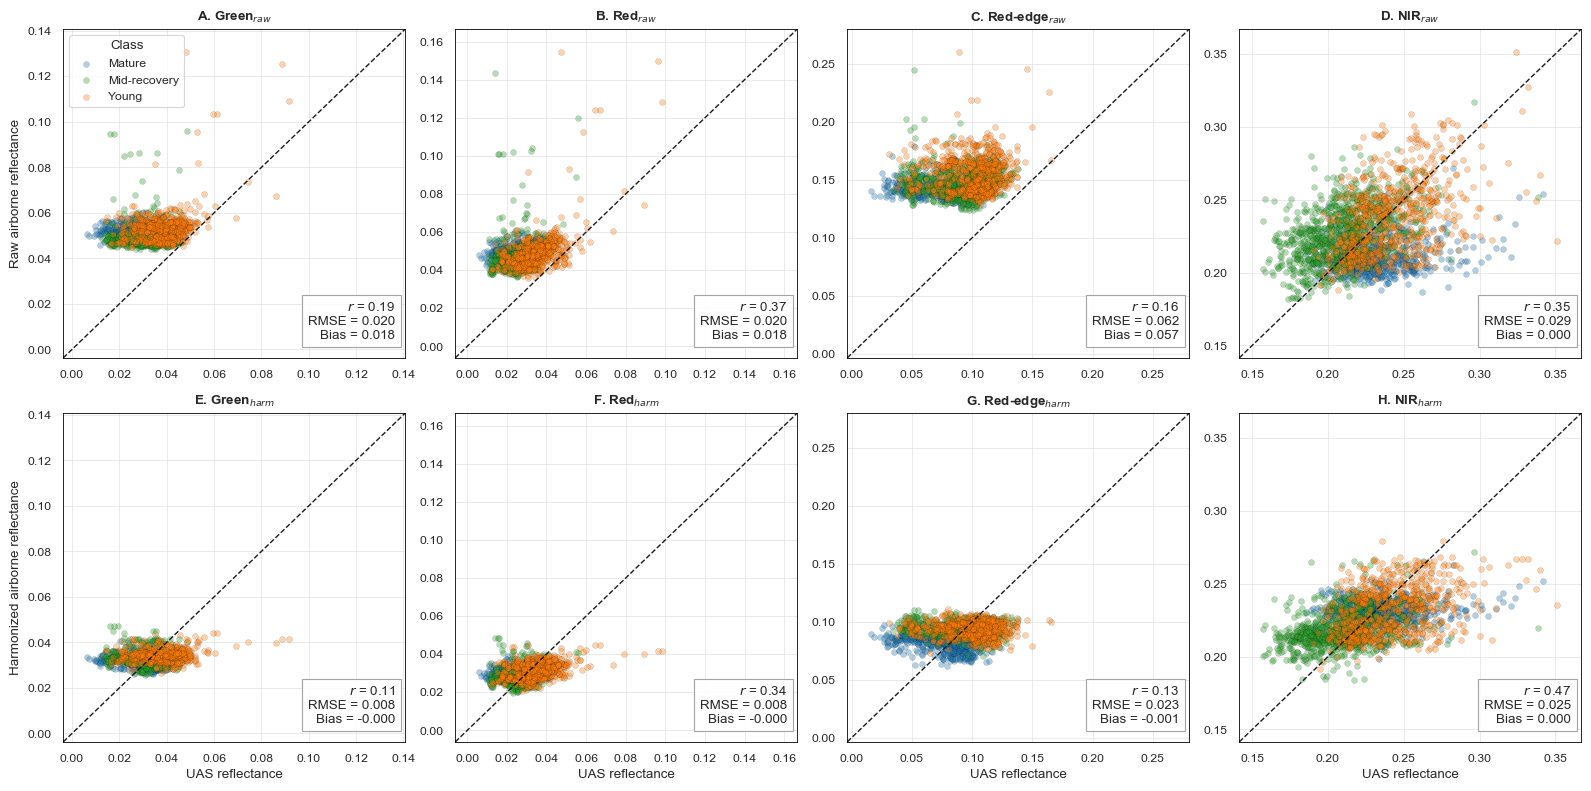

In [14]:
## C5. Plot raw and spatially validated band-level harmonization

TARGET_MAP = {"Green":"UAS_Green", "Red":"UAS_Red", "RedEdge":"UAS_RedEdge", "NIR":"UAS_NIR"}
RAW_ANCHOR_MAP = {"Green":"Raw_Green", "Red":"Raw_Red", "RedEdge":"Raw_RedEdge", "NIR":"Raw_NIR"}
oof_mean = {band: 0.5 * (oof_predictions[("X", band)] + oof_predictions[("Y", band)]) for band in ANCHOR_BANDS}
calibration_recovery = calibration_df["site"].map({
    "BY_2006":"Mature", "BY_2016":"Mid-recovery", "BY_2017_16":"Mid-recovery", "BY_2019":"Young", "BY_2020":"Young"
}).to_numpy()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for j, band in enumerate(ANCHOR_BANDS):
    observed = calibration_df[TARGET_MAP[band]].to_numpy(float)
    raw = calibration_df[RAW_ANCHOR_MAP[band]].to_numpy(float)
    harm = np.asarray(oof_mean[band], float)
    valid = np.isfinite(observed) & np.isfinite(raw) & np.isfinite(harm)
    lo, hi = min(observed[valid].min(), raw[valid].min(), harm[valid].min()), max(observed[valid].max(), raw[valid].max(), harm[valid].max())
    pad = 0.08 * (hi - lo); lims = [lo - pad, hi + pad]

    for cls in ["Mature","Mid-recovery","Young"]:
        m = calibration_recovery == cls
        axes[0,j].scatter(observed[m], raw[m], s=18, color=RECOVERY_COLORS[cls], edgecolor="black", linewidth=0.2, alpha=0.35, label=cls)
        axes[1,j].scatter(observed[m], harm[m], s=18, color=RECOVERY_COLORS[cls], edgecolor="black", linewidth=0.2, alpha=0.35)

    raw_stats, harm_stats = prediction_metrics(observed, raw), prediction_metrics(observed, harm)
    for ax in axes[:,j]:
        ax.plot(lims, lims, "k--", linewidth=1); ax.set_xlim(lims); ax.set_ylim(lims); ax.grid(True, color="0.88", linewidth=0.5)
    axes[0,j].set_title(f"{chr(65+j)}. {band.replace('RedEdge','Red-edge')}$_{{raw}}$", fontweight="bold")
    axes[1,j].set_title(f"{chr(69+j)}. {band.replace('RedEdge','Red-edge')}$_{{harm}}$", fontweight="bold")
    axes[0,j].text(0.97,0.05,f"$r$ = {raw_stats['r']:.2f}\nRMSE = {raw_stats['RMSE']:.3f}\nBias = {raw_stats['Bias']:.3f}", transform=axes[0,j].transAxes, ha="right", va="bottom", bbox=dict(facecolor="white", edgecolor="0.6", alpha=0.9))
    axes[1,j].text(0.97,0.05,f"$r$ = {harm_stats['r']:.2f}\nRMSE = {harm_stats['RMSE']:.3f}\nBias = {harm_stats['Bias']:.3f}", transform=axes[1,j].transAxes, ha="right", va="bottom", bbox=dict(facecolor="white", edgecolor="0.6", alpha=0.9))
    axes[1,j].set_xlabel("UAS reflectance")

axes[0,0].set_ylabel("Raw airborne reflectance"); axes[1,0].set_ylabel("Harmonized airborne reflectance")
axes[0,0].legend(title="Class", loc="upper left"); plt.tight_layout(); plt.show()

PRIMARY COMMON-n=11 GDVI QUADRATIC COMPARISON


,Approach,Index,Form,n,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,UAS,GDVI,Quadratic,11,0.620,0.286,0.444,0.346,0.283
1,Raw airborne MSI,GDVI,Quadratic,11,0.528,0.319,0.249,0.402,0.372
2,Band-harmonized MSI,GDVI,Quadratic,11,0.784,0.216,0.562,0.307,0.290
3,Direct-index-harmonized MSI,GDVI,Quadratic,11,0.766,0.224,0.589,0.297,0.278



PAIRED UNCERTAINTY FOR FIXED COMMON-n=11 GDVI MODELS


,Comparison,Raw_LOOCV_R2,Candidate_LOOCV_R2,Delta_LOOCV_R2,Raw_LOOCV_RMSE,Candidate_LOOCV_RMSE,Observed_RMSE_reduction,Bootstrap_median,CI_2.5,CI_97.5,Fraction_candidate_better,Mean_reference_minus_candidate_loss,p_one_sided_candidate_better,p_two_sided
0,Raw -> Band-harmonized MSI,0.249,0.5617,0.3126,0.4023,0.3074,0.0949,0.0935,-0.0243,0.2066,0.9406,0.0674,0.0869,0.1733
1,Raw -> Direct-index-harmonized MSI,0.249,0.5894,0.3404,0.4023,0.2975,0.1048,0.1028,-0.0029,0.2098,0.9714,0.0734,0.0566,0.1127


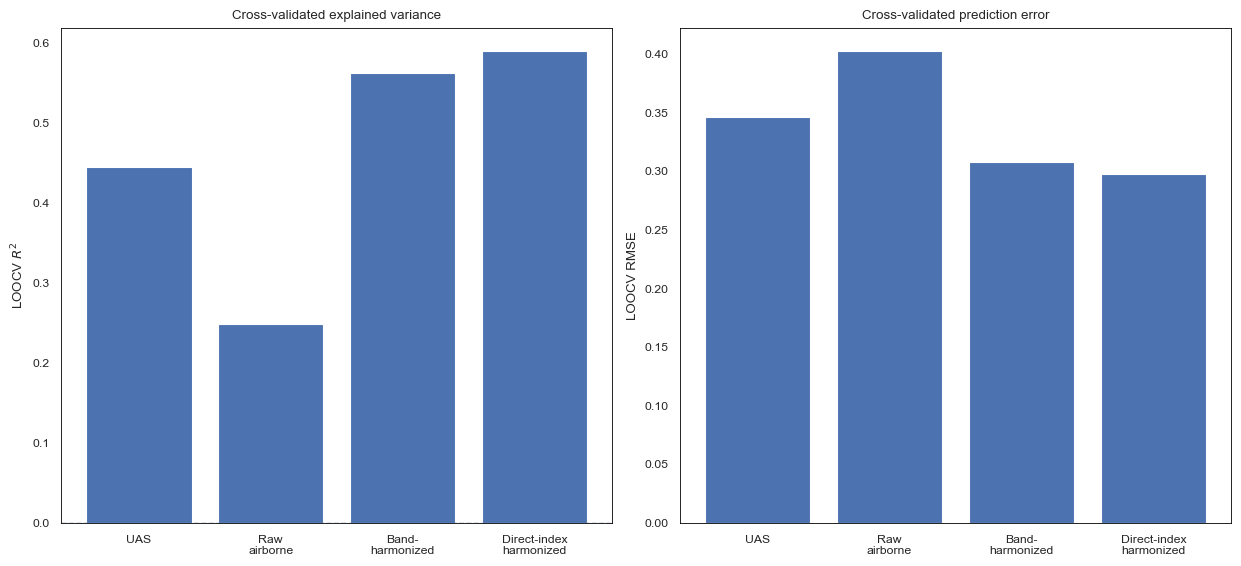

In [15]:
## C6. Primary common-n=11 GDVI comparison

REP_ORDER = ['UAS', 'Raw airborne MSI', 'Band-harmonized MSI', 'Direct-index-harmonized MSI']
primary_msi_n11 = fixed_msi_n11[['Approach', 'Index', 'Form', 'n', 'Full_R2', 'Full_RMSE', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].copy()
primary_msi_n11['Approach'] = pd.Categorical(primary_msi_n11['Approach'], categories=REP_ORDER, ordered=True)
primary_msi_n11 = primary_msi_n11.sort_values('Approach').reset_index(drop=True)

print('PRIMARY COMMON-n=11 GDVI QUADRATIC COMPARISON')
display(primary_msi_n11.round(3))
print('\nPAIRED UNCERTAINTY FOR FIXED COMMON-n=11 GDVI MODELS')
display(paired_gdvi_inference.round(4))
labels = ['UAS', 'Raw\nairborne', 'Band-\nharmonized', 'Direct-index\nharmonized']

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.75))
axes[0].bar(labels, primary_msi_n11['LOOCV_R2'])
axes[0].axhline(0, linestyle='--', linewidth=1)
axes[0].set_ylabel('LOOCV $R^2$')
axes[0].set_title('Cross-validated explained variance')
axes[1].bar(labels, primary_msi_n11['LOOCV_RMSE'])
axes[1].set_ylabel('LOOCV RMSE')
axes[1].set_title('Cross-validated prediction error')
plt.tight_layout()
plt.show()

In [16]:
## D1. Supplementary check: AVIRIS-NG L2A versus L2B

AVIRIS_L2A = {
    "ang20231031t092656_002": Path("../../AVIRIS_NG_data/L2A_data/ang20231031t092656_002_L2A_OE_0b4f48b4_RFL_ORT.nc"),
    "ang20231109t062226_001": Path("../../AVIRIS_NG_data/L2A_data/ang20231109t062226_001_L2A_OE_0b4f48b4_RFL_ORT.nc"),
    "ang20231109t062226_002": Path("../../AVIRIS_NG_data/L2A_data/ang20231109t062226_002_L2A_OE_0b4f48b4_RFL_ORT.nc"),
    "ang20231117t123306_001": Path("../../AVIRIS_NG_data/L2A_data/ang20231117t123306_001_L2A_OE_0b4f48b4_RFL_ORT.nc"),
}

l2a_available = all(path.exists() for path in AVIRIS_L2A.values())
print("L2A sensitivity files available:", l2a_available)

# Supplementary analysis order used below
SUPP_BAND_ORDER = ["Green", "Red", "RedEdge", "NIR"]

# Rectangular-band sensitivity on the same locked calibration population
MAVIC_RECT_WINDOWS = {
    "Green": (560.0, 16.0), "Red": (650.0, 16.0),
    "RedEdge": (730.0, 16.0), "NIR": (860.0, 26.0),
}

raw_rows = []
for band, (obs_col, pred_col) in RAW_TARGET_MAP.items():
    raw_rows.append({"Representation":"Measured SRF (L2B)", "Band":band,
                     **prediction_metrics(calibration_df[obs_col], calibration_df[pred_col])})
raw_correspondence = pd.DataFrame(raw_rows)

rect_anchor_arrays, rect_rows = {}, []
for band, (center, half_width) in MAVIC_RECT_WINDOWS.items():
    m = (wavelengths >= center-half_width) & (wavelengths <= center+half_width)
    rect_anchor_arrays[band] = np.nanmean(spectra_calibration[:, m], axis=1)
    obs_col = RAW_TARGET_MAP[band][0]
    rect_rows.append({"Representation":"Rectangular band", "Band":band,
                      **prediction_metrics(calibration_df[obs_col], rect_anchor_arrays[band])})
srf_sensitivity = pd.concat([raw_correspondence, pd.DataFrame(rect_rows)], ignore_index=True)

# L2A vs L2B band comparison used by the supplementary cell
l2a_raw_comparison = None
if l2a_available:
    l2a_band_matrix = np.full((len(calibration_df), 4), np.nan, dtype=float)
    for scene, l2a_path in AVIRIS_L2A.items():
        l2a_wavelengths = read_wavelengths(l2a_path)
        if len(l2a_wavelengths) != len(wavelengths) or not np.allclose(l2a_wavelengths, wavelengths, rtol=0, atol=0.1):
            raise RuntimeError(f"{scene}: L2A wavelength grid differs from L2B.")
        idx = np.where(calibration_df["scene"].to_numpy() == scene)[0]
        subdataset = f"NETCDF:{l2a_path}:/reflectance/reflectance"
        with rasterio.open(subdataset) as src:
            for k in idx:
                row, col = int(calibration_df.loc[k, "row"]), int(calibration_df.loc[k, "col"])
                spectrum = src.read(window=Window(col, row, 1, 1)).reshape(src.count).astype(float)
                for j, band in enumerate(ANCHOR_BANDS):
                    ii = srf_weights[band]["indices"]; ww = srf_weights[band]["weights"]
                    l2a_band_matrix[k, j] = float(np.sum(spectrum[ii] * ww))

    rows = []
    for j, band in enumerate(ANCHOR_BANDS):
        obs = calibration_df[TARGET_MAP[band]].to_numpy(float)
        rows.append({"Product":"L2A", "Band":band, **prediction_metrics(obs, l2a_band_matrix[:,j])})
        rows.append({"Product":"L2B", "Band":band, **prediction_metrics(obs, calibration_df[f"Raw_{band}"].to_numpy(float))})
    l2a_raw_comparison = pd.DataFrame(rows)

print("Supplementary sensor-diagnostic objects ready.")

SUPP_TABLE_DIR = Path(".")

def save_supp_figure(fig, filename):
    pass


L2A sensitivity files available: True
Supplementary sensor-diagnostic objects ready.


SUPPLEMENTARY — AVIRIS-NG L2A VERSUS L2B FULL-SPECTRUM SENSITIVITY

Full L2A spectra extracted for 2,147 matched pixels.
Common valid spectral channels: 351
Spectral range: 402.2–2445.8 nm

Full-spectrum L2A/L2B similarity summary:


,Metric,Median,Q25,Q75
0,Spectral Pearson r,0.9998,0.9984,0.9998
1,Cosine similarity,1.0000,0.9996,1.0000
2,Spectral angle (deg),0.5575,0.5296,1.6514
3,Spectral NRMSE (%),4.0316,2.7558,15.4571
4,Absolute mean-spectrum difference (%),3.4111,3.1657,3.7131
5,Wavelength-wise pixel correlation,0.9123,0.7269,0.9670



Median pixel-level spectral Pearson r = 0.9998
Median pixel-level cosine similarity = 1.0000
Median spectral angle = 0.558 degrees
Median spectral NRMSE = 4.03%
Median absolute mean-spectrum difference = 3.41%
Median wavelength-wise L2A/L2B pixel correlation = 0.9123


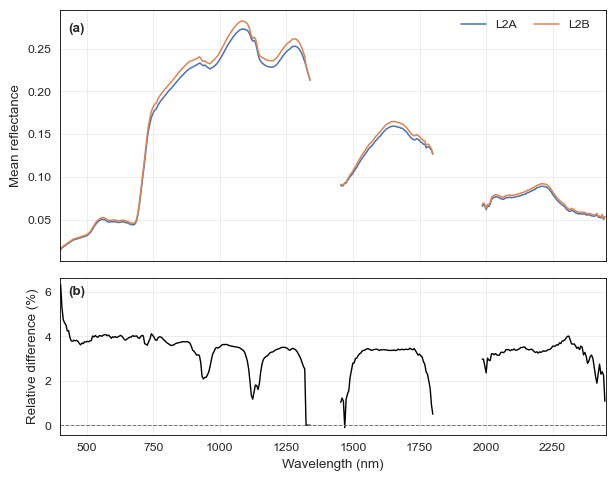


Four-band UAS correspondence sensitivity:


,Band,n,r_L2A,r_L2B,Delta_r_L2A_minus_L2B,RMSE_L2A,RMSE_L2B,Delta_RMSE_L2A_minus_L2B,Bias_L2A,Bias_L2B
0,Green,2147,0.2608,0.1856,0.0752,0.0182,0.0199,-0.0018,0.0158,0.0177
1,Red,2147,0.2959,0.3747,-0.0787,0.0193,0.0204,-0.0011,0.0165,0.0183
2,RedEdge,2147,0.2929,0.1588,0.1341,0.0571,0.0620,-0.0048,0.0518,0.0573
3,NIR,2147,0.0139,0.3514,-0.3376,0.0411,0.0290,0.0121,-0.0079,0.0002


L2A had higher UAS Pearson r in 2/4 bands.
L2A had lower UAS RMSE in 3/4 bands.


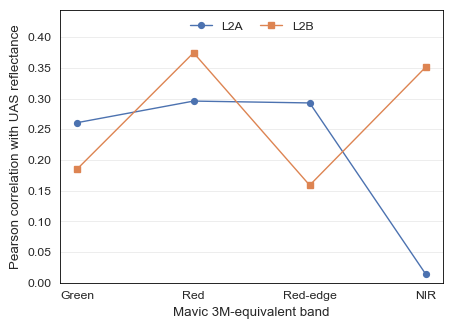

In [17]:
## D2. L2A/L2B full-spectrum and four-band sensitivity

n_pixels = len(calibration_df)
n_bands = len(wavelengths)
l2a_spectra_calibration = np.full((n_pixels, n_bands), np.nan, dtype=float)

for scene, l2a_path in AVIRIS_L2A.items():
    scene_idx = np.where(calibration_df['scene'].to_numpy() == scene)[0]
    if len(scene_idx) == 0:
        continue
    l2a_wavelengths = np.asarray(read_wavelengths(l2a_path), dtype=float)
    if len(l2a_wavelengths) != len(wavelengths) or not np.allclose(l2a_wavelengths, wavelengths, rtol=0, atol=0.1):
        raise RuntimeError(f'{scene}: L2A wavelength grid differs from the locked L2B wavelength grid.')
    l2a_subdataset = f'NETCDF:{l2a_path}:/reflectance/reflectance'
    l2b_path = AVIRIS_L2B[scene]
    l2b_subdataset = f'NETCDF:{l2b_path}:/reflectance/reflectance'
    with rasterio.open(l2a_subdataset) as src_a, rasterio.open(l2b_subdataset) as src_b:
        if src_a.crs != src_b.crs or src_a.width != src_b.width or src_a.height != src_b.height or (src_a.count != src_b.count):
            raise RuntimeError(f'{scene}: L2A/L2B raster geometry differs.')
        if not np.allclose(tuple(src_a.transform), tuple(src_b.transform), rtol=0, atol=1e-08):
            raise RuntimeError(f'{scene}: L2A/L2B transforms differ.')
        for out_i in scene_idx:
            row = int(calibration_df.loc[out_i, 'row'])
            col = int(calibration_df.loc[out_i, 'col'])
            spectrum = src_a.read(window=rasterio.windows.Window(col, row, 1, 1)).reshape(-1).astype(float)
            if len(spectrum) != n_bands:
                raise RuntimeError(f'{scene}: unexpected L2A spectral length.')
            l2a_spectra_calibration[out_i, :] = spectrum
if not np.isfinite(l2a_spectra_calibration).all():
    bad_rows = np.where(~np.all(np.isfinite(l2a_spectra_calibration), axis=1))[0]
    raise RuntimeError(f'L2A full-spectrum extraction contains {len(bad_rows)} incomplete observations.')

print('=' * 74)
print('SUPPLEMENTARY — AVIRIS-NG L2A VERSUS L2B FULL-SPECTRUM SENSITIVITY')
print('=' * 74)
print(f'\nFull L2A spectra extracted for {len(l2a_spectra_calibration):,} matched pixels.')
l2b_spectra_calibration = np.asarray(spectra_calibration, dtype=float)
finite_l2a = np.all(np.isfinite(l2a_spectra_calibration), axis=0)
finite_l2b = np.all(np.isfinite(l2b_spectra_calibration), axis=0)
nonconstant_l2a = np.nanstd(l2a_spectra_calibration, axis=0) > 1e-09
nonconstant_l2b = np.nanstd(l2b_spectra_calibration, axis=0) > 1e-09
supp_valid_hsi_mask = spectral_range_ok & ~strong_h2o & finite_l2a & finite_l2b & nonconstant_l2a & nonconstant_l2b
supp_valid_wavelengths = wavelengths[supp_valid_hsi_mask]

A = l2a_spectra_calibration[:, supp_valid_hsi_mask]
B = l2b_spectra_calibration[:, supp_valid_hsi_mask]
print(f'Common valid spectral channels: {A.shape[1]}')
print(f'Spectral range: {supp_valid_wavelengths.min():.1f}–{supp_valid_wavelengths.max():.1f} nm')
mean_l2a_spectrum = np.mean(A, axis=0)
mean_l2b_spectrum = np.mean(B, axis=0)
mean_difference = mean_l2b_spectrum - mean_l2a_spectrum
relative_mean_difference_pct = 100.0 * mean_difference / np.where(np.abs(mean_l2a_spectrum) > 1e-08, mean_l2a_spectrum, np.nan)
A_col_centered = A - np.mean(A, axis=0, keepdims=True)
B_col_centered = B - np.mean(B, axis=0, keepdims=True)
numerator_lambda = np.sum(A_col_centered * B_col_centered, axis=0)
denominator_lambda = np.sqrt(np.sum(A_col_centered ** 2, axis=0) * np.sum(B_col_centered ** 2, axis=0))
r_by_wavelength = np.divide(numerator_lambda, denominator_lambda, out=np.full_like(numerator_lambda, np.nan, dtype=float), where=denominator_lambda > 0)
wavelength_summary = pd.DataFrame({'Wavelength_nm': supp_valid_wavelengths, 'Mean_L2A': mean_l2a_spectrum, 'Mean_L2B': mean_l2b_spectrum, 'L2B_minus_L2A': mean_difference, 'Relative_difference_percent': relative_mean_difference_pct, 'Pixelwise_r_L2A_vs_L2B': r_by_wavelength})
A_row_centered = A - np.mean(A, axis=1, keepdims=True)
B_row_centered = B - np.mean(B, axis=1, keepdims=True)
spectral_corr_num = np.sum(A_row_centered * B_row_centered, axis=1)
spectral_corr_den = np.sqrt(np.sum(A_row_centered ** 2, axis=1) * np.sum(B_row_centered ** 2, axis=1))
spectral_r = np.divide(spectral_corr_num, spectral_corr_den, out=np.full(len(A), np.nan, dtype=float), where=spectral_corr_den > 0)
dot_products = np.sum(A * B, axis=1)
norm_products = np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1)
cosine_similarity = np.divide(dot_products, norm_products, out=np.full(len(A), np.nan, dtype=float), where=norm_products > 0)
cosine_similarity = np.clip(cosine_similarity, -1.0, 1.0)
spectral_angle_deg = np.degrees(np.arccos(cosine_similarity))
spectral_rmse = np.sqrt(np.mean((B - A) ** 2, axis=1))
mean_abs_l2a = np.mean(np.abs(A), axis=1)
spectral_nrmse_pct = 100.0 * spectral_rmse / np.where(mean_abs_l2a > 1e-08, mean_abs_l2a, np.nan)
spectral_similarity_df = pd.DataFrame({'scene': calibration_df['scene'].to_numpy(), 'site': calibration_df['site'].to_numpy(), 'row': calibration_df['row'].to_numpy(), 'col': calibration_df['col'].to_numpy(), 'Spectral_r': spectral_r, 'Cosine_similarity': cosine_similarity, 'Spectral_angle_deg': spectral_angle_deg, 'Spectral_RMSE': spectral_rmse, 'Spectral_NRMSE_percent': spectral_nrmse_pct})

def q25(x):
    return float(np.nanpercentile(x, 25))

def q75(x):
    return float(np.nanpercentile(x, 75))
supp_l2_full_spectrum_summary = pd.DataFrame({'Metric': ['Spectral Pearson r', 'Cosine similarity', 'Spectral angle (deg)', 'Spectral NRMSE (%)', 'Absolute mean-spectrum difference (%)', 'Wavelength-wise pixel correlation'], 'Median': [np.nanmedian(spectral_r), np.nanmedian(cosine_similarity), np.nanmedian(spectral_angle_deg), np.nanmedian(spectral_nrmse_pct), np.nanmedian(np.abs(relative_mean_difference_pct)), np.nanmedian(r_by_wavelength)], 'Q25': [q25(spectral_r), q25(cosine_similarity), q25(spectral_angle_deg), q25(spectral_nrmse_pct), q25(np.abs(relative_mean_difference_pct)), q25(r_by_wavelength)], 'Q75': [q75(spectral_r), q75(cosine_similarity), q75(spectral_angle_deg), q75(spectral_nrmse_pct), q75(np.abs(relative_mean_difference_pct)), q75(r_by_wavelength)]})
print('\nFull-spectrum L2A/L2B similarity summary:')
display(supp_l2_full_spectrum_summary.round(4))
print(f'\nMedian pixel-level spectral Pearson r = {np.nanmedian(spectral_r):.4f}')
print(f'Median pixel-level cosine similarity = {np.nanmedian(cosine_similarity):.4f}')
print(f'Median spectral angle = {np.nanmedian(spectral_angle_deg):.3f} degrees')
print(f'Median spectral NRMSE = {np.nanmedian(spectral_nrmse_pct):.2f}%')
print(f'Median absolute mean-spectrum difference = {np.nanmedian(np.abs(relative_mean_difference_pct)):.2f}%')
print(f'Median wavelength-wise L2A/L2B pixel correlation = {np.nanmedian(r_by_wavelength):.4f}')

mean_l2a_plot = np.full(len(wavelengths), np.nan, dtype=float)
mean_l2b_plot = np.full(len(wavelengths), np.nan, dtype=float)
relative_difference_plot = np.full(len(wavelengths), np.nan, dtype=float)
mean_l2a_plot[supp_valid_hsi_mask] = mean_l2a_spectrum
mean_l2b_plot[supp_valid_hsi_mask] = mean_l2b_spectrum
relative_difference_plot[supp_valid_hsi_mask] = relative_mean_difference_pct

fig, axes = plt.subplots(2, 1, figsize=(6.5, 5.38), sharex=True, gridspec_kw={'height_ratios': [1.6, 1.0], 'hspace': 0.08})
ax1, ax2 = axes
ax1.plot(wavelengths, mean_l2a_plot, linewidth=1.1, label='L2A')
ax1.plot(wavelengths, mean_l2b_plot, linewidth=1.1, label='L2B')
ax1.set_ylabel('Mean reflectance')
ax1.text(0.015, 0.95, '(a)', transform=ax1.transAxes, ha='left', va='top', fontweight='bold')
ax1.legend(frameon=False, loc='upper right', bbox_to_anchor=(0.98, 0.98), ncol=2, handlelength=2.0, columnspacing=1.4, borderaxespad=0.0)
ax2.plot(wavelengths, relative_difference_plot, color='black', linewidth=1.0)
ax2.axhline(0, color='0.45', linewidth=0.7, linestyle='--')
ax2.set_xlabel('Wavelength (nm)')
ax2.set_ylabel('Relative difference (%)')
ax2.text(0.015, 0.95, '(b)', transform=ax2.transAxes, ha='left', va='top', fontweight='bold')
for ax in axes:
    ax.set_xlim(400, 2450)
    ax.grid(True, color='0.88', linewidth=0.4)
    ax.set_axisbelow(True)
    ax.tick_params(axis='both', length=2.5, width=0.6)
    for spine in ax.spines.values():
        spine.set_linewidth(0.6)
fig.subplots_adjust(left=0.14, right=0.98, bottom=0.11, top=0.9)
plt.show()

l2_processing_rows = []
for band in SUPP_BAND_ORDER:
    temp = l2a_raw_comparison[l2a_raw_comparison['Band'] == band].copy()
    l2a_row = temp[temp['Product'] == 'L2A'].iloc[0]
    l2b_row = temp[temp['Product'] == 'L2B'].iloc[0]
    l2_processing_rows.append({'Band': band, 'n': int(min(l2a_row['n'], l2b_row['n'])), 'r_L2A': float(l2a_row['r']), 'r_L2B': float(l2b_row['r']), 'Delta_r_L2A_minus_L2B': float(l2a_row['r'] - l2b_row['r']), 'RMSE_L2A': float(l2a_row['RMSE']), 'RMSE_L2B': float(l2b_row['RMSE']), 'Delta_RMSE_L2A_minus_L2B': float(l2a_row['RMSE'] - l2b_row['RMSE']), 'Bias_L2A': float(l2a_row['Bias']), 'Bias_L2B': float(l2b_row['Bias'])})
supp_l2a_l2b = pd.DataFrame(l2_processing_rows)

print('\nFour-band UAS correspondence sensitivity:')
display(supp_l2a_l2b.round(4))
n_l2a_r_better = int((supp_l2a_l2b['Delta_r_L2A_minus_L2B'] > 0).sum())
n_l2a_rmse_better = int((supp_l2a_l2b['Delta_RMSE_L2A_minus_L2B'] < 0).sum())
print(f'L2A had higher UAS Pearson r in {n_l2a_r_better}/4 bands.')
print(f'L2A had lower UAS RMSE in {n_l2a_rmse_better}/4 bands.')
plot_df = supp_l2a_l2b.set_index('Band').loc[SUPP_BAND_ORDER]
x = np.arange(len(SUPP_BAND_ORDER))
r_l2a = plot_df['r_L2A'].to_numpy(float)
r_l2b = plot_df['r_L2B'].to_numpy(float)

fig, ax = plt.subplots(figsize=(4.62, 3.38))
ax.plot(x, r_l2a, marker='o', markersize=4.2, linewidth=1.0, label='L2A')
ax.plot(x, r_l2b, marker='s', markersize=4.0, linewidth=1.0, label='L2B')
ax.set_xticks(x)
ax.set_xticklabels(['Green', 'Red', 'Red-edge', 'NIR'])
ax.set_ylabel('Pearson correlation with UAS reflectance')
ax.set_xlabel('Mavic 3M-equivalent band')
ax.set_ylim(0, max(np.nanmax(r_l2a), np.nanmax(r_l2b)) + 0.07)
ax.grid(True, axis='y', color='0.88', linewidth=0.4)
ax.grid(False, axis='x')
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper center', ncol=2, handlelength=1.8, columnspacing=1.4)
ax.tick_params(axis='both', length=2.5, width=0.6)
for spine in ax.spines.values():
    spine.set_linewidth(0.6)
fig.tight_layout()
plt.show()

SUPPLEMENTARY — RECTANGULAR VERSUS MEASURED MAVIC 3M SRFs

A. Effect on UAS–AVIRIS agreement


,Band,n,r_Rectangular,r_Measured_SRF,Delta_r_SRF_minus_Rectangular,RMSE_Rectangular,RMSE_Measured_SRF,Delta_RMSE_SRF_minus_Rectangular,Bias_Rectangular,Bias_Measured_SRF
0,Green,2147,0.18992,0.18565,-0.00427,0.02049,0.01994,-0.00056,0.01833,0.01774
1,Red,2147,0.37449,0.37465,0.00016,0.02039,0.02043,0.00004,0.01823,0.01828
2,RedEdge,2147,0.16454,0.15882,-0.00572,0.06615,0.06199,-0.00416,0.06165,0.05725
3,NIR,2147,0.35260,0.35141,-0.00118,0.02899,0.02897,-0.00002,0.00105,0.00024



B. Direct effect on synthesized AVIRIS reflectance


,Band,n,Mean_Rectangular,Mean_Measured_SRF,Mean_SRF_minus_Rectangular,Median_SRF_minus_Rectangular,Mean_change_percent,RMSE_SRF_vs_Rectangular,r_SRF_vs_Rectangular
0,Green,2147,0.05182,0.05122,-0.00059,-0.00057,-1.14415,0.00063,0.99967
1,Red,2147,0.04821,0.04826,0.00005,0.00005,0.10679,0.00008,0.99998
2,RedEdge,2147,0.15270,0.14830,-0.00440,-0.00425,-2.88113,0.00449,0.99889
3,NIR,2147,0.22701,0.22620,-0.00081,-0.00080,-0.35697,0.00082,0.99999



Maximum absolute change in UAS–AVIRIS Pearson r after replacing rectangular bands with measured SRFs: 0.0057
Maximum absolute mean reflectance change associated with SRF convolution: 2.88%


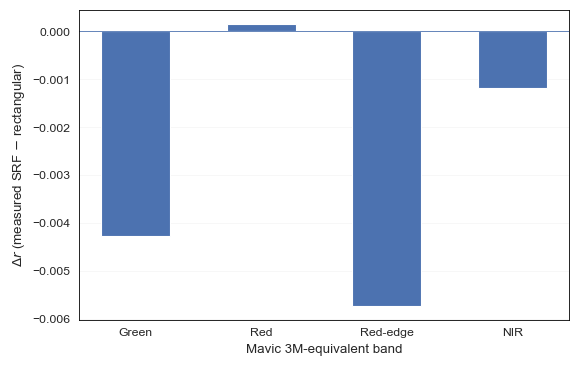

In [18]:
## D3. Rectangular bands versus measured Mavic 3M SRFs

srf_agreement_rows = []
for band in SUPP_BAND_ORDER:
    measured = srf_sensitivity[(srf_sensitivity['Band'] == band) & (srf_sensitivity['Representation'] == 'Measured SRF (L2B)')].iloc[0]
    rectangular = srf_sensitivity[(srf_sensitivity['Band'] == band) & (srf_sensitivity['Representation'] == 'Rectangular band')].iloc[0]
    srf_agreement_rows.append({'Band': band, 'n': int(measured['n']), 'r_Rectangular': float(rectangular['r']), 'r_Measured_SRF': float(measured['r']), 'Delta_r_SRF_minus_Rectangular': float(measured['r'] - rectangular['r']), 'RMSE_Rectangular': float(rectangular['RMSE']), 'RMSE_Measured_SRF': float(measured['RMSE']), 'Delta_RMSE_SRF_minus_Rectangular': float(measured['RMSE'] - rectangular['RMSE']), 'Bias_Rectangular': float(rectangular['Bias']), 'Bias_Measured_SRF': float(measured['Bias'])})

supp_srf_agreement = pd.DataFrame(srf_agreement_rows)
srf_direct_rows = []
for band in SUPP_BAND_ORDER:
    measured = np.asarray(calibration_df[f'Raw_{band}'], dtype=float)
    rectangular = np.asarray(rect_anchor_arrays[band], dtype=float)
    valid = np.isfinite(measured) & np.isfinite(rectangular)
    measured = measured[valid]
    rectangular = rectangular[valid]
    delta = measured - rectangular
    mean_rect = float(np.mean(rectangular))
    mean_delta = float(np.mean(delta))
    pct_change = 100.0 * mean_delta / mean_rect if not np.isclose(mean_rect, 0.0) else np.nan
    r_between = float(pearsonr(rectangular, measured).statistic)
    srf_direct_rows.append({'Band': band, 'n': int(valid.sum()), 'Mean_Rectangular': mean_rect, 'Mean_Measured_SRF': float(np.mean(measured)), 'Mean_SRF_minus_Rectangular': mean_delta, 'Median_SRF_minus_Rectangular': float(np.median(delta)), 'Mean_change_percent': pct_change, 'RMSE_SRF_vs_Rectangular': float(np.sqrt(np.mean(delta ** 2))), 'r_SRF_vs_Rectangular': r_between})
supp_srf_direct = pd.DataFrame(srf_direct_rows)

print('=' * 72)
print('SUPPLEMENTARY — RECTANGULAR VERSUS MEASURED MAVIC 3M SRFs')
print('=' * 72)
print('\nA. Effect on UAS–AVIRIS agreement')
display(supp_srf_agreement.round(5))
print('\nB. Direct effect on synthesized AVIRIS reflectance')
display(supp_srf_direct.round(5))
max_abs_delta_r = float(np.max(np.abs(supp_srf_agreement['Delta_r_SRF_minus_Rectangular'])))
max_abs_pct_change = float(np.max(np.abs(supp_srf_direct['Mean_change_percent'])))
print(f'\nMaximum absolute change in UAS–AVIRIS Pearson r after replacing rectangular bands with measured SRFs: {max_abs_delta_r:.4f}')
print(f'Maximum absolute mean reflectance change associated with SRF convolution: {max_abs_pct_change:.2f}%')
plot_df = supp_srf_agreement.set_index('Band').loc[SUPP_BAND_ORDER]
x = np.arange(len(SUPP_BAND_ORDER))

fig, ax = plt.subplots(figsize=(5.88, 3.75))
ax.bar(x, plot_df['Delta_r_SRF_minus_Rectangular'].to_numpy(float), width=0.55)
ax.axhline(0, linewidth=0.6)
ax.set_xticks(x)
ax.set_xticklabels(['Green', 'Red', 'Red-edge', 'NIR'])
ax.set_xlabel('Mavic 3M-equivalent band')
ax.set_ylabel('$\\Delta r$ (measured SRF $-$ rectangular)')
ax.grid(True, axis='y', linewidth=0.4, alpha=0.45)
ax.grid(False, axis='x')
ax.set_axisbelow(True)
ax.tick_params(axis='both', length=2.5, width=0.6)
for spine in ax.spines.values():
    spine.set_linewidth(0.6)
fig.tight_layout()
plt.show()

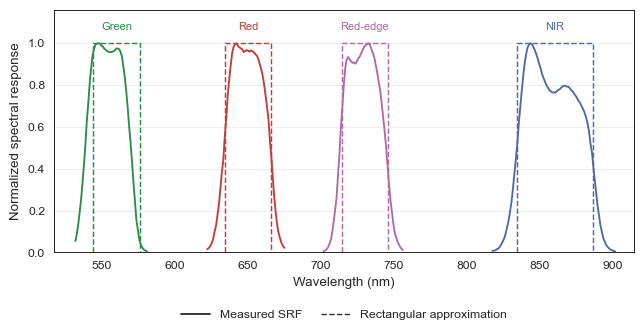

In [19]:
## D4. Plot measured and rectangular Mavic 3M spectral responses

required_srf_objects = ['native_srf', 'MAVIC_RECT_WINDOWS']
missing_srf_objects = [name for name in required_srf_objects if name not in globals()]
if missing_srf_objects:
    raise RuntimeError('Run the main notebook first. Missing objects:\n  - ' + '\n  - '.join(missing_srf_objects))
band_order = ['Green', 'Red', 'RedEdge', 'NIR']
band_labels = {'Green': 'Green', 'Red': 'Red', 'RedEdge': 'Red-edge', 'NIR': 'NIR'}
band_colors = {'Green': '#2b8c4b', 'Red': '#c43c39', 'RedEdge': '#b26aa5', 'NIR': '#5269a5'}

support_wavelengths = []
for band in band_order:
    wl, response = native_srf[band]
    wl = np.asarray(wl, dtype=float)
    response = np.clip(np.asarray(response, dtype=float), 0, None)
    if np.nanmax(response) > 0:
        response_norm = response / np.nanmax(response)
        support = response_norm >= 0.01
        support_wavelengths.extend(wl[support].tolist())
    center, half_width = MAVIC_RECT_WINDOWS[band]
    support_wavelengths.extend([center - half_width, center + half_width])
    
x_min = np.min(support_wavelengths) - 15
x_max = np.max(support_wavelengths) + 15
fig, ax = plt.subplots(figsize=(6.75, 3.85))
for band in band_order:
    color = band_colors[band]
    wl, response = native_srf[band]
    wl = np.asarray(wl, dtype=float)
    response = np.clip(np.asarray(response, dtype=float), 0, None)
    if np.nanmax(response) <= 0:
        continue
    response_norm = response / np.nanmax(response)
    ax.plot(wl, response_norm, color=color, linewidth=1.35, linestyle='-', zorder=3)
    center, half_width = MAVIC_RECT_WINDOWS[band]
    lower = center - half_width
    upper = center + half_width
    ax.plot([lower, lower, upper, upper], [0, 1, 1, 0], color=color, linewidth=1.05, linestyle='--', zorder=2)
    ax.text(center, 1.055, band_labels[band], color=color, ha='center', va='bottom', fontsize=8)
ax.set_xlim(x_min, x_max)
ax.set_ylim(0, 1.16)
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Normalized spectral response')
ax.grid(True, axis='y', color='0.88', linewidth=0.4)
ax.grid(False, axis='x')
ax.set_axisbelow(True)
ax.tick_params(axis='both', length=2.5, width=0.6)
for spine in ax.spines.values():
    spine.set_linewidth(0.6)
legend_handles = [Line2D([0], [0], color='0.20', linewidth=1.35, linestyle='-', label='Measured SRF'), Line2D([0], [0], color='0.20', linewidth=1.05, linestyle='--', label='Rectangular approximation')]
ax.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, -0.19), ncol=2, frameon=False, handlelength=2.4, columnspacing=1.5)
fig.subplots_adjust(left=0.12, right=0.98, bottom=0.27, top=0.9)
plt.show()

SUPPLEMENTARY — COREGISTRATION SENSITIVITY
Native-pixel shift magnitude: 6.50 m
Offsets tested: 9

Pixels retained with valid UAS support at all nine offsets:


,site,candidate_pixels,common_pixels_all_offsets
0,BY_2006,250,205
1,BY_2016,250,199
2,BY_2019,250,196
3,BY_2020,250,192
4,BY_2017_16,250,199



Zero shift versus site-specific highest-r offset (diagnostic only; offsets are NOT adopted):


,site,Mean_r_zero,Mean_RMSE_zero,n_common,best_dx_m,best_dy_m,Mean_r_best,Mean_RMSE_best,Delta_Mean_r,Best_shift_distance_m
0,BY_2006,0.0988,0.0322,205,6.5,0.0,0.3099,0.0320,0.2111,6.5
1,BY_2016,0.3943,0.0252,199,0.0,0.0,0.3943,0.0252,0.0000,0.0
2,BY_2017_16,0.4761,0.0280,199,0.0,0.0,0.4761,0.0280,0.0000,0.0
3,BY_2019,0.5253,0.0207,196,0.0,0.0,0.5253,0.0207,0.0000,0.0
4,BY_2020,0.3401,0.0314,192,6.5,0.0,0.4206,0.0312,0.0805,6.5



Mean response for each COMMON offset across all site-band combinations:


,dx_m,dy_m,Mean_r_across_site_band,SD_r_across_site_band,Mean_RMSE_across_site_band
0,-6.5,-6.5,0.1534,0.1585,0.0294
3,0.0,-6.5,0.2530,0.1623,0.0285
6,6.5,-6.5,0.2241,0.1708,0.0295
1,-6.5,0.0,0.1898,0.1588,0.0291
4,0.0,0.0,0.3669,0.2041,0.0275
7,6.5,0.0,0.3642,0.1731,0.0285
2,-6.5,6.5,0.1328,0.1679,0.0300
5,0.0,6.5,0.2375,0.1782,0.0290
8,6.5,6.5,0.2547,0.1764,0.0299



Common-offset comparison:
Zero shift mean r = 0.3669
Highest mean-r common offset = (0.00, 0.00) m
Highest common-offset mean r = 0.3669
Δ mean r relative to zero = 0.0000


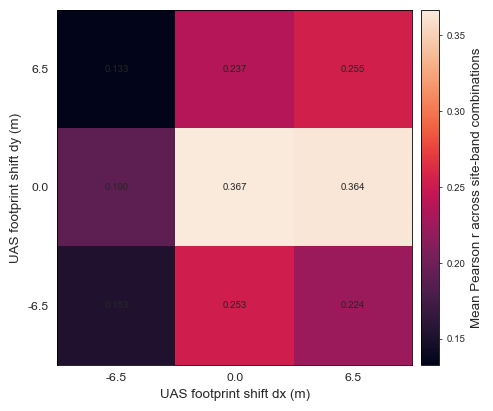

In [20]:
## D5. Coregistration sensitivity using common support

offset_m = float(native_pixel_edge_m)
offset_values = [-offset_m, 0.0, offset_m]
offset_pairs = list(product(offset_values, offset_values))
print('=' * 72)
print('SUPPLEMENTARY — COREGISTRATION SENSITIVITY')
print('=' * 72)
print(f'Native-pixel shift magnitude: {offset_m:.2f} m')
print(f'Offsets tested: {len(offset_pairs)}')

coreg_common_rows = []
coreg_common_site_counts = []
for site, uas_path in UAS_FILES.items():
    site_df = calibration_df[calibration_df['site'] == site].sort_values(['row', 'col']).reset_index(drop=True)
    if len(site_df) == 0:
        continue
    if len(site_df) > 250:
        sample_pos = np.linspace(0, len(site_df) - 1, 250).round().astype(int)
        site_df = site_df.iloc[np.unique(sample_pos)].copy()
    candidate_n = len(site_df)
    retained_ids = []
    with rasterio.open(uas_path) as uas_src:
        av_to_uas = Transformer.from_crs(reference_aviris_crs, uas_src.crs, always_xy=True)
        for rec in site_df.itertuples(index=False):
            info = scene_spatial_info[rec.scene]
            transform = info['transform']
            row = int(rec.row)
            col = int(rec.col)
            poly_av = Polygon([transform * (col, row), transform * (col + 1, row), transform * (col + 1, row + 1), transform * (col, row + 1)])
            poly_uas = shapely_transform(av_to_uas.transform, poly_av)
            offset_aggregates = {}
            valid_all_offsets = True
            for dx, dy in offset_pairs:
                shifted = shapely_translate(poly_uas, xoff=dx, yoff=dy)
                agg = aggregate_uas_inside_polygon(uas_src, shifted)
                if agg is None:
                    valid_all_offsets = False
                    break
                if agg['support_valid_fraction'] < STRICT_INTERIOR_VALID_FRACTION or agg['uas_valid_fraction'] < STRICT_INTERIOR_VALID_FRACTION:
                    valid_all_offsets = False
                    break
                offset_aggregates[dx, dy] = agg
            if not valid_all_offsets:
                continue
            sample_id = f'{site}|{rec.scene}|{row}|{col}'
            retained_ids.append(sample_id)
            for (dx, dy), agg in offset_aggregates.items():
                for band in SUPP_BAND_ORDER:
                    coreg_common_rows.append({'sample_id': sample_id, 'site': site, 'scene': rec.scene, 'row': row, 'col': col, 'dx_m': float(dx), 'dy_m': float(dy), 'Band': band, 'UAS_reflectance': float(agg[f'UAS_{band}']), 'AVIRIS_reflectance': float(getattr(rec, f'Raw_{band}'))})
    coreg_common_site_counts.append({'site': site, 'candidate_pixels': int(candidate_n), 'common_pixels_all_offsets': int(len(retained_ids))})
coreg_common_df = pd.DataFrame(coreg_common_rows)
coreg_common_counts = pd.DataFrame(coreg_common_site_counts)

if coreg_common_df.empty:
    raise RuntimeError('No common-support coregistration observations were retained.')
print('\nPixels retained with valid UAS support at all nine offsets:')
display(coreg_common_counts)
metric_rows = []
for (site, dx, dy, band), group in coreg_common_df.groupby(['site', 'dx_m', 'dy_m', 'Band'], sort=True):
    x = group['AVIRIS_reflectance'].to_numpy(float)
    y = group['UAS_reflectance'].to_numpy(float)
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]
    if len(x) < 10:
        continue
    if np.std(x) > 0 and np.std(y) > 0:
        r_value = float(pearsonr(x, y).statistic)
    else:
        r_value = np.nan
    metric_rows.append({'site': site, 'dx_m': float(dx), 'dy_m': float(dy), 'Band': band, 'n': int(len(x)), 'r': r_value, 'RMSE': float(np.sqrt(np.mean((x - y) ** 2))), 'Bias_AVIRIS_minus_UAS': float(np.mean(x - y))})
supp_coreg_band_metrics = pd.DataFrame(metric_rows)
supp_coreg_site_summary = supp_coreg_band_metrics.groupby(['site', 'dx_m', 'dy_m'], as_index=False).agg(Mean_r=('r', 'mean'), Mean_RMSE=('RMSE', 'mean'), Mean_abs_bias=('Bias_AVIRIS_minus_UAS', lambda values: np.mean(np.abs(values))), n_common=('n', 'first'))
zero_site = supp_coreg_site_summary[np.isclose(supp_coreg_site_summary['dx_m'], 0.0) & np.isclose(supp_coreg_site_summary['dy_m'], 0.0)].copy()
best_site = supp_coreg_site_summary.sort_values(['site', 'Mean_r'], ascending=[True, False]).groupby('site', as_index=False).first()
supp_coreg_site_comparison = zero_site[['site', 'Mean_r', 'Mean_RMSE', 'n_common']].rename(columns={'Mean_r': 'Mean_r_zero', 'Mean_RMSE': 'Mean_RMSE_zero'}).merge(best_site[['site', 'dx_m', 'dy_m', 'Mean_r', 'Mean_RMSE']].rename(columns={'dx_m': 'best_dx_m', 'dy_m': 'best_dy_m', 'Mean_r': 'Mean_r_best', 'Mean_RMSE': 'Mean_RMSE_best'}), on='site', how='left')
supp_coreg_site_comparison['Delta_Mean_r'] = supp_coreg_site_comparison['Mean_r_best'] - supp_coreg_site_comparison['Mean_r_zero']
supp_coreg_site_comparison['Best_shift_distance_m'] = np.sqrt(supp_coreg_site_comparison['best_dx_m'] ** 2 + supp_coreg_site_comparison['best_dy_m'] ** 2)
supp_coreg_global_summary = supp_coreg_band_metrics.groupby(['dx_m', 'dy_m'], as_index=False).agg(Mean_r_across_site_band=('r', 'mean'), SD_r_across_site_band=('r', 'std'), Mean_RMSE_across_site_band=('RMSE', 'mean'))
global_zero = supp_coreg_global_summary[np.isclose(supp_coreg_global_summary['dx_m'], 0.0) & np.isclose(supp_coreg_global_summary['dy_m'], 0.0)].iloc[0]
global_best = supp_coreg_global_summary.sort_values('Mean_r_across_site_band', ascending=False).iloc[0]

print('\nZero shift versus site-specific highest-r offset (diagnostic only; offsets are NOT adopted):')
display(supp_coreg_site_comparison.round(4))
print('\nMean response for each COMMON offset across all site-band combinations:')
display(supp_coreg_global_summary.sort_values(['dy_m', 'dx_m']).round(4))
print('\nCommon-offset comparison:')
print(f"Zero shift mean r = {global_zero['Mean_r_across_site_band']:.4f}")
print(f"Highest mean-r common offset = ({global_best['dx_m']:.2f}, {global_best['dy_m']:.2f}) m")
print(f"Highest common-offset mean r = {global_best['Mean_r_across_site_band']:.4f}")
print(f"Δ mean r relative to zero = {global_best['Mean_r_across_site_band'] - global_zero['Mean_r_across_site_band']:.4f}")
surface = supp_coreg_global_summary.pivot(index='dy_m', columns='dx_m', values='Mean_r_across_site_band').sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(5.04, 4.2))
image = ax.imshow(surface.to_numpy(float), aspect='equal')
ax.set_xticks(np.arange(len(surface.columns)))
ax.set_xticklabels([f'{value:.1f}' for value in surface.columns])
ax.set_yticks(np.arange(len(surface.index)))
ax.set_yticklabels([f'{value:.1f}' for value in surface.index])
ax.set_xlabel('UAS footprint shift dx (m)')
ax.set_ylabel('UAS footprint shift dy (m)')
for i in range(surface.shape[0]):
    for j in range(surface.shape[1]):
        value = float(surface.iloc[i, j])
        ax.text(j, i, f'{value:.3f}', ha='center', va='center', fontsize=7)
cbar = fig.colorbar(image, ax=ax, pad=0.02, fraction=0.05)
cbar.set_label('Mean Pearson r across site-band combinations')
cbar.ax.tick_params(labelsize=7, length=2.5, width=0.6)
cbar.outline.set_linewidth(0.6)
ax.tick_params(axis='both', length=2.5, width=0.6)
for spine in ax.spines.values():
    spine.set_linewidth(0.6)
fig.tight_layout()
plt.show()

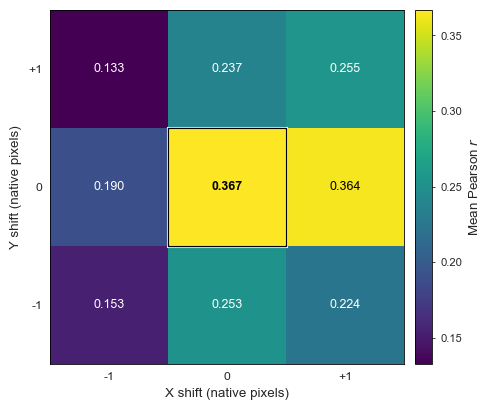

In [21]:
## D6. Plot the common-offset coregistration sensitivity

if 'supp_coreg_global_summary' not in globals():
    raise RuntimeError('Run the common-support coregistration analysis cell first.')
if 'offset_m' not in globals():
    offset_m = float(native_pixel_edge_m)
shift_values_m = np.array([-offset_m, 0.0, offset_m], dtype=float)
heat = np.full((3, 3), np.nan, dtype=float)
for i, dy in enumerate(shift_values_m):
    for j, dx in enumerate(shift_values_m):
        match = supp_coreg_global_summary[np.isclose(supp_coreg_global_summary['dx_m'], dx) & np.isclose(supp_coreg_global_summary['dy_m'], dy)]
        if len(match) != 1:
            raise RuntimeError(f'Expected one coregistration result for dx={dx}, dy={dy}; found {len(match)}.')
        heat[i, j] = float(match['Mean_r_across_site_band'].iloc[0])
        
fig, ax = plt.subplots(figsize=(4.93, 4.19))
cmap = plt.get_cmap('viridis')
image = ax.imshow(heat, origin='lower', cmap=cmap, aspect='equal')
ax.set_xticks([0, 1, 2])
ax.set_yticks([0, 1, 2])
ax.set_xticklabels(['-1', '0', '+1'])
ax.set_yticklabels(['-1', '0', '+1'])
ax.set_xlabel('X shift (native pixels)')
ax.set_ylabel('Y shift (native pixels)')
norm = image.norm
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat[i, j]
        rgba = cmap(norm(value))
        luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        text_color = 'black' if luminance > 0.55 else 'white'
        ax.text(j, i, f'{value:.3f}', ha='center', va='center', color=text_color, fontsize=9, fontweight='bold' if i == 1 and j == 1 else 'normal')
zero_outer = Rectangle((0.5, 0.5), 1, 1, fill=False, edgecolor='white', linewidth=2.2, zorder=5)
zero_inner = Rectangle((0.5, 0.5), 1, 1, fill=False, edgecolor='black', linewidth=1.0, zorder=6)
ax.add_patch(zero_outer)
ax.add_patch(zero_inner)
cbar = fig.colorbar(image, ax=ax, orientation='vertical', pad=0.025, fraction=0.05)
cbar.set_label('Mean Pearson $r$')
cbar.ax.tick_params(labelsize=8, length=2.5, width=0.6)
cbar.outline.set_linewidth(0.6)
ax.tick_params(axis='both', length=2.5, width=0.6)
for spine in ax.spines.values():
    spine.set_linewidth(0.6)
fig.tight_layout()
plt.show()